# GLENDA Endometriosis Dataset: Exploratory Data Analysis
**Author:** Jessica Janko

## Table of Contents

### Dataset Introduction

- [Dataset Overview](#Dataset-Overview)
- [Environment Setup](#Environment-Setup)
- [Helper Functions](#Helper-Functions)
- [Data Loading and Organization](#Data-Loading-and-Organization)


### Exploratory Data Analysis

- [1. Dataset Overview and Integrity](#1.-Dataset-Overview-and-Integrity)
  - [1.1 Dataset Composition and Frequency Distributions](#1.1-Dataset-Composition-and-Frequency-Distributions)
  - [1.2 Dataset Integrity and Annotation Validation](#1.2-Dataset-Integrity-and-Annotation-Validation)
  - [1.3 Data Cleaning](#1.3-Data-Cleaning)
- [2. Lesion Annotation Characteristics](#2.-Lesion-Annotation-Characteristics)
  - [2.1 Annotation Size Statistics](#2.1-Annotation-Size-Statistics)
  - [2.2 Annotation Size Distribution](#2.2-Annotation-Size-Distribution)
  - [2.3 Annotation Outlier Analysis](#2.3-Annotation-Outlier-Analysis)
  - [2.4 Spatial Distribution of Lesions](#2.4-Spatial-Distribution-of-Lesions)
- [3. Image Quality and Color Metrics](#3.-Image-Quality-and-Color-Metrics)
  - [3.1 Brightness Analysis](#3.1-Brightness-Analysis)
  - [3.2 Contrast Analysis](#3.2-Contrast-Analysis)
  - [3.3 Sharpness Analysis](#3.3-Sharpness-Analysis)
  - [3.4 RGB Color Channel Intensity Analysis](#3.4-RGB-Color-Channel-Intensity-Analysis)
- [4. Dataset Visual Exploration and Annotation Visualization](#4.-Dataset-Visual-Exploration-and-Annotation-Visualization)
  - [4.1 Sample Image Visualization](#4.1-Sample-Image-Visualization)
  - [4.2 Annotation Overlay Visualization](#4.2-Annotation-Overlay-Visualization)
  - [4.3 Multi-Label Image Annotation Visualization](#4.3-Multi-Label-Image-Annotation-Visualization)
- [5. Visual Image Quality Assessment](#5.-Visual-Image-Quality-Assessment)
  - [5.1 Brightness Extremes](#5.1-Brightness-Extremes)
  - [5.2 Contrast Extremes](#5.2-Contrast-Extremes)
  - [5.3 Sharpness Extremes](#5.3-Sharpness-Extremes)
  - [5.4 Identified Data Characteristics and Quality Concerns](#5.4-Identified-Data-Characteristics-and-Quality-Concerns)
- [6. Image Similarity and Redundancy Analysis](#6.-Image-Similarity-and-Redundancy-Analysis)
  - [6.1 Visual Inspection of Consecutive Frames](#6.1-Visual-Inspection-of-Consecutive-Frames)
  - [6.2 SSIM Analysis](#6.2-SSIM-Analysis)
- [Summary of EDA Findings](#Summary-of-EDA-Findings)
- [Overall Dataset Considerations](#Overall-Dataset-Considerations)

# Dataset Introduction

## Dataset Overview

**GLENDA** (Gynecologic Laparoscopy ENdometriosis DAtaset) is a medical imaging dataset containing over 25,000 images collected during more than 400 gynecologic laparoscopy surgeries. The dataset was created to support the development of automated approaches to endometriosis recognition.

<u>Key Features:<u>
* Two image groups: `no_pathology` (images without endometriosis) and `pathology` (images containing endometriosis)
* Pixel-level annotations for four lesion categories:
  1. Peritoneum: Endometriosis found on the peritoneum, which is the lining of the abdominal and pelvic cavity. It is considered one of the most common subtypes of endometriosis and can appear as red, black, or white lesions.
  2. Ovary: Endometriosis found on or within the ovaries, which can sometimes form endometriomas (also called "chocolate cysts").
  3. Uterus: Endometriosis found on the outer uterine surface. Often coexists with adenomyosis, which is found within the uterine muscle.
  4. DIE (deep infiltrating endometriosis): Endometriosis that invasively grows deep into pelvic structures and organs and can be found in a variety of locations, including the rectum, uterosacral ligaments, bladder, and the rectovaginal space. Due to its complexity, it does not have a distinct visual appearance. 

### Structure
The GLENDA dataset is organized into separate `no_pathology` and `pathology` directories. The observed directory hierarchy is shown below:
```
DS
  - no_pathology
      - frames 
          - v_<vID>_s_<FROM-TO>
              - f_<fID>.jpg
  - pathology
      - annotations
          - v_<vID>_s_<FROM-TO>
              - f_<fID>
                  - <CLASS>_a_<aID>.png
      - frames
          - v_<vID>_s_<FROM-TO>
              - f_<fID>.jpg or f_<fID>_a.jpg (an "_a" suffix means an annotation exists for that image)
statistics
  - annotations.csv
  - images.csv
Readme.txt
```
The dataset documentation defines identifiers for videos (`v_vID`), frames (`f_fID`), annotations (`a_aID`), and sequences (`s_FROM-TO`), which have the following definitions:
    
| Identifier | Meaning                         | 
| :--------- | :-------------------------------| 
|   v_vID    | Video (v) with ID (vID)         | 
|   f_fID    | Frame (f) with ID (fID)         |
|   a_aID    | Annotation (a) with ID (aID)    |
| s_FROM-TO  | Video sequence (s) with starting <br> frame (FROM) and ending frame (TO) |
|   CLASS    | Lesion category                 |

### File Types and Formats
The dataset contains two file types. Below are the details about each type and what they represent:
| File Type  | Format | Description |
| :--------- | :----- | :---------- |
| Images     | .jpg   | RGB frames captured during laparoscopic surgery |
| Annotations| .png   | Binary masks where 0 (black) indicates the absence <br> of a lesion and 255 (white) indicates the presence of a lesion |

### Citation
A. Leibetseder, S. Kletz, K. Schoeffmann, S. Keckstein and J. Keckstein. 2020. GLENDA: Gynecologic Laparoscopy Endometriosis Dataset. In Proceedings of the 26th International Conference on Multimedia Modeling, MMM 2020. Springer, Cham.

DOI: https://doi.org/10.1007/978-3-030-37734-2_36

### Access Information
* Source: https://ftp.itec.aau.at/datasets/GLENDA/v1_0/
* License: CC BY-NC 4.0 https://creativecommons.org/licenses/by-nc/4.0/

### Usage Restrictions
This project is strictly for **educational and non-commercial research purposes only**.
Any alternative use requires explicit permission from the source of the surgical videos, Prof. Dr. Jörg Keckstein (contact: [joerg@keckstein.at](mailto:joerg@keckstein.at)).

## Environment Setup
Import required libraries, set a random seed for reproducibility, and define global visualization parameters to maintain consistent figure formatting throughout the notebook.

In [1]:
from pathlib import Path
from collections import defaultdict, Counter
import random
import hashlib

import numpy as np
import pandas as pd
from PIL import Image

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches # Create custom legend for lesion-color pairings
from matplotlib.colors import LinearSegmentedColormap # Custom gradient from lesion colors for consistent figure palette 

from scipy.ndimage import gaussian_filter # Smooth centroid density heatmaps
from skimage.filters import laplace #  Laplacian sharpness analysis
from skimage.measure import find_contours # Annotation visualization
from skimage.metrics import structural_similarity as ssim # Image similarity analysis

%matplotlib inline
plt.style.use("seaborn-v0_8-whitegrid")
mpl.rcParams["axes.spines.top"] = False
mpl.rcParams["axes.spines.right"] = False
mpl.rcParams["grid.alpha"] = 0.20

mpl.rcParams["figure.figsize"] = (8, 5)
mpl.rcParams["figure.dpi"] = 100
mpl.rcParams["savefig.dpi"] = 100
mpl.rcParams["font.size"] = 10

random.seed(23)
np.random.seed(23)

## Helper Functions
- `extract_annotation_features()` - extract annotation properties (area, centroid coordinates, lesion type) for a given annotation file path.
- `compare_image_groups()` - displays side-by-side comparisons between two image groups of equal length, with optional metric information.
- `visualize_image_annotations()` - visualize lesion annotations overlaid on corresponding pathology images.
- `sequential_ssim_analysis()` - compute and visualize SSIM-based similarity distributions across sequential frame pairs.
- `randomized_ssim_analysis()` - compute and visualize SSIM-based similarity distributions across randomized frame pairs.

In [2]:
def extract_annotation_features(ann):
    annotation_array = np.array(Image.open(ann))
    binary_ann = annotation_array > 0

    ys, xs = np.where(binary_ann)

    if len(xs) == 0:
        return {
            "area": 0,
            "x": np.nan,
            "y": np.nan,
            "lesion_type": ann.stem.split('_')[0],
            "annotation_path": ann}

    area = np.count_nonzero(annotation_array)
    x_centroid = xs.mean()
    y_centroid = ys.mean()

    lesion_type = ann.stem.split('_')[0]

    return {
        "area": area,
        "x": x_centroid,
        "y": y_centroid,
        "lesion_type": lesion_type,
        "annotation_path": ann}

In [3]:
# Visual comparison of sample images from two groups
def compare_image_groups(group1, group2, group1_label, group2_label, group1_values = None, group2_values = None, value_label = None, title = None):
    # Raise value error if two groups are not the same length
    if len(group1) != len(group2):
        raise ValueError(
            f"Groups must be the same size for side-by-side comparison."
            f"There are {len(group1)} images in group1 and {len(group2)} images in group2.")

    n = len(group1)
    fig, axes = plt.subplots(nrows = 2, ncols = n, figsize=(15, 5.5))

    for i in range(n):
        axes[0, i].imshow(Image.open(group1[i]))
        axes[0, i].axis("off")
        
        axes[1, i].imshow(Image.open(group2[i]))
        axes[1, i].axis("off")
        
        if group1_values is not None:
            axes[0, i].set_title(f"{value_label}: {group1_values[i]:.3f}", fontsize = 9)
        if group2_values is not None:
            axes[1, i].set_title(f"{value_label}: {group2_values[i]:.3f}", fontsize = 9)
        
    fig.text(0.02, 0.87, group1_label, fontsize = 12, fontweight = "bold", va = "center")
    fig.text(0.02, 0.47, group2_label, fontsize = 12, fontweight = "bold", va ="center")
    if title is None:
        title = f"{group1_label} vs. {group2_label}"
    plt.suptitle(title, fontsize = 14)
    
    plt.tight_layout()           
    plt.show() 

In [4]:
# Lesion colors used to distinguish categories in annotation overlays
lesion_colors = {
    "peritoneum": "purple",
    "die": "deeppink",
    "uterus": "greenyellow",
    "ovary": "orange"
}

# Visualize pathology images with annotation overlays
def visualize_image_annotations(annotation_groups):
    for annotation_parent in annotation_groups:
        
        # Find the pathology image associated with the current annotation group
        # Annotation files and images are stored separately, so their paths
        # must be matched using their shared directory structure
        for img in pathology_images:
            # Filter out images from differently named parent directories
            if img.parent.name != annotation_parent.parent.name:
                continue
            # Convert image and annotation paths to a shared identifier
            # Example:
            # Image: pathology/frames/v_1002_s_499-499/f_499_a.jpg
            # Annotations: pathology/annotations/v_1002_s_499-499/f_499
            # Identifier: v_1002_s_499-499/f_499
            img_key = f"{img.parent.name}/{img.stem.split('_')[0]}_{img.stem.split('_')[1]}"
            ann_key = annotation_parent.relative_to(Path("GLENDA_v1.0/DS/pathology/annotations")).as_posix()

            # Match between image and annotation group
            if img_key == ann_key:
                image_path = img
                break
            
        lap_image = plt.imread(image_path)
        
        # Identify lesion categories present in the annotation group
        present_lesions = {annotation_path.name.split("_")[0] for annotation_path in annotations_by_parent[annotation_parent]}
        
        plt.figure()
        plt.imshow(lap_image)
        plt.axis('off')
        plt.title(f"Annotated Pathology Image ({', '.join(sorted(present_lesions))})")
        
        # Overlay annotation contours on the pathology image
        for annotation_path in annotations_by_parent[annotation_parent]:
            annotation = plt.imread(annotation_path)
            
            lesion = annotation_path.name.split("_")[0]
            color = lesion_colors.get(lesion, "white")

            # Convert annotations into binary format and extract contours
            annotation_pixels = annotation > 0
            contours = find_contours(annotation_pixels, 0.5)

            # Draw annotation contours on top of the pathology image
            for contour in contours:
                plt.plot(contour[:,1], contour[:,0], linewidth = 2, color = color)
                
        # Create a legend for lesion categories present in the image
        legend_handles = [mpatches.Patch(color=lesion_colors[l], label=l) for l in present_lesions]
        plt.legend(handles=legend_handles, loc= "center left", bbox_to_anchor=(1, 0.5))
        
        plt.show()

In [5]:
# Create custom gradient
cmap = LinearSegmentedColormap.from_list("cmap_palette", ["purple", "deeppink", "orange", "greenyellow"])

def sequential_ssim_analysis(sequences_dict, dataset_name):
    scores = []
    # Compare adjacent image pairs within each video sequence
    for paths in sequences_dict.values():
        for i in range(len(paths) - 1):
            # Convert images to grayscale ("L") to compare structural patterns
            # Grayscale pixel values range from 0 (black) to 255 (white)
            # Normalize pixel values to [0, 1] for SSIM computation
            img1 = np.array(Image.open(paths[i]).convert("L")).astype(np.float32) / 255.0
            img2 = np.array(Image.open(paths[i  + 1]).convert("L")).astype(np.float32) / 255.0

            # Compute structural similarity between the two images
            score = ssim(img1, img2, data_range = 1.0)
            scores.append(score)
        
    scores = np.array(scores)
    total_pairs = len(scores)
    
    # Summary SSIM statistics
    print("\n SSIM Analysis")
    print(f"Average SSIM: {scores.mean():.3f}")
    print(f"Std SSIM: {scores.std():.3f}")
    print(f"Min SSIM: {scores.min():.3f}")
    print(f"Max SSIM: {scores.max():.3f}")

    # Plot histogram of SSIM scores
    plt.figure()
    
    # Use Freedman-Diaconis (FD) rule for number of bins
    counts, bins, patches = plt.hist(scores, bins = "fd", edgecolor = "black")
    norm = plt.Normalize(vmin = min(scores), vmax = max(scores))
    
    # Apply color gradient to each histogram bin based on its SSIM value
    for patch, left_edge in zip(patches, bins[:-1]):
        patch.set_facecolor(cmap(norm(left_edge)))
    plt.title(f"SSIM Distribution of {dataset_name} ({total_pairs} pairs)")
    plt.xlabel("Sequential SSIM")
    plt.ylabel("Frequency")
    plt.show()

def randomized_ssim_analysis(image_list, n_pairs, dataset_name):
    scores = []
    # Determine the total number of valid adjacent pairs
    total_pairs = min(n_pairs, len(image_list) - 1)

    # Compare adjacent images within the randomized ordering 
    for i in range(total_pairs):
        img1 = np.array(Image.open(image_list[i]).convert("L")).astype(np.float32) / 255.0
        img2 = np.array(Image.open(image_list[i  + 1]).convert("L")).astype(np.float32) / 255.0

        score = ssim(img1, img2, data_range = 1.0)
        scores.append(score)
        
    scores = np.array(scores)

    # Summary SSIM Statistics
    print("\n SSIM Analysis")
    print(f"Average SSIM: {scores.mean():.3f}")
    print(f"Std SSIM: {scores.std():.3f}")
    print(f"Min SSIM: {scores.min():.3f}")
    print(f"Max SSIM: {scores.max():.3f}")

    # Plot histogram of SSIM scores
    plt.figure()
    counts, bins, patches = plt.hist(scores, bins = "fd", edgecolor = "black")
    norm = plt.Normalize(vmin = min(scores), vmax = max(scores))

    for patch, left_edge in zip(patches, bins[:-1]):
        patch.set_facecolor(cmap(norm(left_edge)))
        
    plt.title(f"SSIM Distribution of {dataset_name} ({total_pairs} pairs)")
    plt.xlabel("Randomized SSIM")
    plt.ylabel("Frequency")
    plt.show()

## Data Loading and Organization
Load image and annotation data from the GLENDA dataset, organize annotations by their corresponding parent directories, summarize lesion types present within each annotation group, and validate the annotation organization structure.

### Image and Annotation File Loading
Collect image and annotation file paths from the GLENDA dataset directories.

In [6]:
# Load image file paths from the GLENDA no_pathology directory
# Defined by the dataset as no_pathology cases
no_pathology_images = []
for file in Path("GLENDA_v1.0/DS/no_pathology").rglob("*.jpg"):
    no_pathology_images.append(file)

In [7]:
# Load image file paths from the GLENDA pathology directory
# Defined by the dataset as pathology cases
pathology_images = []
for file in Path("GLENDA_v1.0/DS/pathology").rglob("*.jpg"):
    pathology_images.append(file)

In [8]:
# Load annotation file paths for pathology cases from the GLENDA dataset
# Annotations correspond to labeled regions of endometriosis lesions
pathology_annotations = []
for file in Path("GLENDA_v1.0/DS/pathology").rglob("*.png"):
    pathology_annotations.append(file)
print(len(pathology_annotations))

520


### Annotation Organization
Group annotation files by their parent directories to organize multiple annotations associated with the same frame, with each parent directory corresponding to an annotated image.

In [9]:
# Group annotation files by their parent directories
annotations_by_parent = defaultdict(list)
for ann in pathology_annotations:
    annotation_parent = ann.parent
    annotations_by_parent[annotation_parent].append(ann)

### Lesion Types by Annotation Group
Summarize the lesion types found within each annotation group and identify multi-label cases.

In [10]:
# Identify all unique lesion types present within each annotation group
lesion_types_by_group = {}

for annotation_parent, ann_list in annotations_by_parent.items():
    types = []
    
    # Extract lesion type from each annotation filename
    # Each annotation filename contains lesion category as its prefix 
    for ann in ann_list:
        lesion_type = ann.stem.split('_')[0]
        types.append(lesion_type)
        
    # Store unique lesion types for each annotation group
    lesion_types_by_group[annotation_parent] = set(types) 

In [11]:
# Identify annotation groups containing multiple lesion types
# These represent multi-label cases in the dataset
multi_label_groups = []
for annotation_parent, types in lesion_types_by_group.items():
    if len(types) > 1:
        multi_label_groups.append(annotation_parent)

### Annotation Group Organization Check
Verify that annotation files and multi-label cases are correctly grouped.

In [12]:
for annotation_parent in sorted(annotations_by_parent.keys())[:10]:
    print("\nAnnotation Directory:", annotation_parent.relative_to(Path("GLENDA_v1.0/DS/pathology/annotations")))
    for annotation_path in annotations_by_parent[annotation_parent]:
        print(" -", annotation_path)


Annotation Directory: v_1002_s_499-499\f_499
 - GLENDA_v1.0\DS\pathology\annotations\v_1002_s_499-499\f_499\peritoneum_a_403.png

Annotation Directory: v_1002_s_91-91\f_91
 - GLENDA_v1.0\DS\pathology\annotations\v_1002_s_91-91\f_91\ovary_a_402.png

Annotation Directory: v_1004_s_869-869\f_869
 - GLENDA_v1.0\DS\pathology\annotations\v_1004_s_869-869\f_869\die_a_404.png

Annotation Directory: v_1044_s_1545-1545\f_1545
 - GLENDA_v1.0\DS\pathology\annotations\v_1044_s_1545-1545\f_1545\peritoneum_a_406.png

Annotation Directory: v_1058_s_1034-1034\f_1034
 - GLENDA_v1.0\DS\pathology\annotations\v_1058_s_1034-1034\f_1034\peritoneum_a_407.png

Annotation Directory: v_1058_s_1254-1254\f_1254
 - GLENDA_v1.0\DS\pathology\annotations\v_1058_s_1254-1254\f_1254\die_a_408.png

Annotation Directory: v_1099_s_261-261\f_261
 - GLENDA_v1.0\DS\pathology\annotations\v_1099_s_261-261\f_261\peritoneum_a_412.png
 - GLENDA_v1.0\DS\pathology\annotations\v_1099_s_261-261\f_261\peritoneum_a_413.png

Annotation D

In [13]:
print("\nMulti-Label Annotations:")
for annotation_parent in sorted(multi_label_groups):
    print("\nAnnotation Directory:", annotation_parent.relative_to(Path("GLENDA_v1.0/DS/pathology/annotations")))
    for annotation_path in annotations_by_parent[annotation_parent]:
        print(" -", annotation_path)


Multi-Label Annotations:

Annotation Directory: v_1320_s_653-653\f_653
 - GLENDA_v1.0\DS\pathology\annotations\v_1320_s_653-653\f_653\die_a_454.png
 - GLENDA_v1.0\DS\pathology\annotations\v_1320_s_653-653\f_653\peritoneum_a_453.png

Annotation Directory: v_1853_s_510-510\f_510
 - GLENDA_v1.0\DS\pathology\annotations\v_1853_s_510-510\f_510\die_a_545.png
 - GLENDA_v1.0\DS\pathology\annotations\v_1853_s_510-510\f_510\peritoneum_a_544.png

Annotation Directory: v_2087_s_1816-1816\f_1816
 - GLENDA_v1.0\DS\pathology\annotations\v_2087_s_1816-1816\f_1816\die_a_571.png
 - GLENDA_v1.0\DS\pathology\annotations\v_2087_s_1816-1816\f_1816\peritoneum_a_570.png

Annotation Directory: v_2403_s_1001-1052\f_1001
 - GLENDA_v1.0\DS\pathology\annotations\v_2403_s_1001-1052\f_1001\die_a_628.png
 - GLENDA_v1.0\DS\pathology\annotations\v_2403_s_1001-1052\f_1001\peritoneum_a_627.png

Annotation Directory: v_2607_s_284-479\f_284
 - GLENDA_v1.0\DS\pathology\annotations\v_2607_s_284-479\f_284\die_a_636.png
 - GL

# Exploratory Data Analysis

## 1. Dataset Overview and Integrity
Summarize the composition of the GLENDA dataset, assess the integrity of the image and annotation data, and remove identified duplicates and invalid annotations for subsequent exploratory analysis.

### 1.1 Dataset Composition and Frequency Distributions

The statistics directory contains two files: `images.csv` and `annotations.csv`, which summarize image and annotation information.

The `images.csv` contains image counts for the `pathology` and `no_pathology` groups.

In [14]:
image_stats = pd.read_csv("GLENDA_v1.0/statistics/images.csv")
image_stats

,label,img_count
0,pathology,12244
1,no_pathology,13438


The `annotations.csv` file contains annotation statistics for each lesion class.

In [15]:
annotations_stats = pd.read_csv("GLENDA_v1.0/statistics/annotations.csv")
annotations_stats

,label,annot_count,annot_img_count,img_count,max_annots_per_image
0,peritoneum,402,203,6470,9
1,ovary,51,48,2478,2
2,die,53,43,2821,3
3,uterus,14,8,475,3
4,no_pathology,0,0,13438,0
5,total,520,302,25682,9


#### 1.1.1 Overall Dataset Counts
Summarize the number of no_pathology and pathology images, annotation files and groups, unannotated pathology images, and total images.

In [16]:
total_images = pathology_images + no_pathology_images
dataset_summary_df = pd.DataFrame({
    "Dataset Component": [
        "Total Images", 
        "no_pathology Images",
        "pathology Images", 
        "Annotation Files",
        "Annotation Groups (Images)",
        "Unannotated Pathology Images"],
    "Count": [
        len(total_images),
        len(no_pathology_images),
        len(pathology_images),
        len(pathology_annotations),
        len(annotations_by_parent),
        len(pathology_images) - len(annotations_by_parent)]})
dataset_summary_df

,Dataset Component,Count
0,Total Images,25682
1,no_pathology Images,13438
2,pathology Images,12244
3,Annotation Files,520
4,Annotation Groups (Images),302
5,Unannotated Pathology Images,11942


The calculated overall dataset counts match the values reported in the official GLENDA dataset documentation and provided statistics files, `images.csv` and `annotations.csv`, confirming consistency with the expected counts.

#### 1.1.2 Image Dimension Summary
Verify consistency of image dimensions across the dataset.

In [17]:
dimension_counts = Counter()
images_list = no_pathology_images + pathology_images
for img_path in images_list:
    dimension_counts[Image.open(img_path).size] += 1

dimension_summary_df = pd.DataFrame({
    "Image Dimensions": list(dimension_counts.keys()),
    "Number of Images": list(dimension_counts.values())})

dimension_summary_df

,Image Dimensions,Number of Images
0,"(640, 360)",25682


All images across both the no_pathology and pathology groups have consistent dimensions of 640 x 360 pixels.

#### 1.1.3 Annotation-Level Lesion Distribution
Summarize the frequency of each lesion category across all pixel-level annotations to assess class distribution at the annotation level.

In [18]:
# Analyze lesion type distribution across annotation files
lesion_annotation_freq = Counter()

for ann_list in annotations_by_parent.values():
    for ann in ann_list:
        lesion_type = ann.stem.split('_')[0]
        lesion_annotation_freq[lesion_type] += 1

annotation_distribution_df = pd.DataFrame({
    "Label": ["peritoneum", "die", "ovary", "uterus", "Total"],
    "Count": [
        lesion_annotation_freq["peritoneum"],
        lesion_annotation_freq["die"],
        lesion_annotation_freq["ovary"],
        lesion_annotation_freq["uterus"],
        sum(lesion_annotation_freq.values())]})

annotation_distribution_df 

,Label,Count
0,peritoneum,402
1,die,53
2,ovary,51
3,uterus,14
4,Total,520


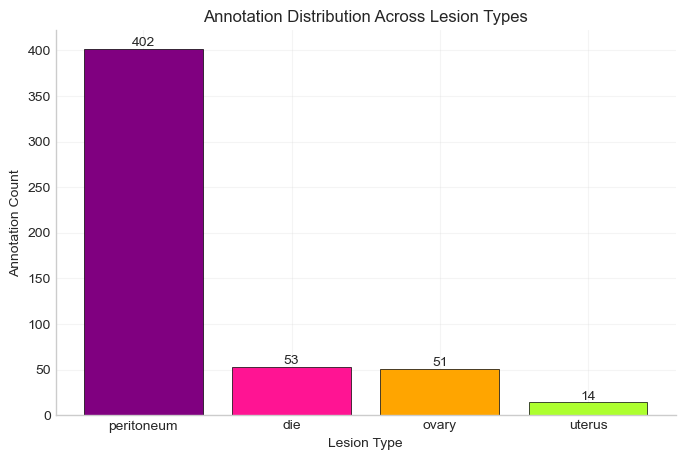

In [19]:
# Sort lesion categories by descending frequency
lesion_annotation_freq_sorted = pd.Series(lesion_annotation_freq).sort_values(ascending = False)

lesion_types = lesion_annotation_freq_sorted.index
annotation_counts = lesion_annotation_freq_sorted.values

bar_colors = [lesion_colors[lesion] for lesion in lesion_types]

bars = plt.bar(lesion_types, 
               annotation_counts, 
               color = bar_colors,
               edgecolor = "black",
               linewidth = 0.5)

plt.bar_label(bars)
plt.xlabel("Lesion Type")
plt.ylabel("Annotation Count")
plt.title("Annotation Distribution Across Lesion Types")

plt.show()

#### 1.1.4 Image-Level Lesion Distribution 
Summarize the frequency of each lesion category across annotated images, represented by annotation groups, to assess class distribution at the image level.

In [20]:
# Analyze lesion type distribution across annotated images
lesion_image_freq = Counter()

# Count each lesion type once per image
for lesions in lesion_types_by_group.values():
    for l in lesions:
        lesion_image_freq[l] += 1

image_distribution_df = pd.DataFrame({
    "Label": ["peritoneum", "die", "ovary", "uterus", "Total"],
    "Count": [
        lesion_image_freq["peritoneum"],
        lesion_image_freq["die"],
        lesion_image_freq["ovary"],
        lesion_image_freq["uterus"],
        sum(lesion_image_freq.values())]})

image_distribution_df

,Label,Count
0,peritoneum,203
1,die,49
2,ovary,48
3,uterus,8
4,Total,308


In [21]:
print(f"Annotated Images: {len(annotations_by_parent)}")
print(f"Multi-Label Images: {len(multi_label_groups)}")
print(f"Total Image Frequency Count: {sum(lesion_image_freq.values())}")

Annotated Images: 302
Multi-Label Images: 6
Total Image Frequency Count: 308


The six multi-label images contribute to multiple lesion category counts, producing the observed difference between total image-level lesion counts (308) and unique annotated images (302).

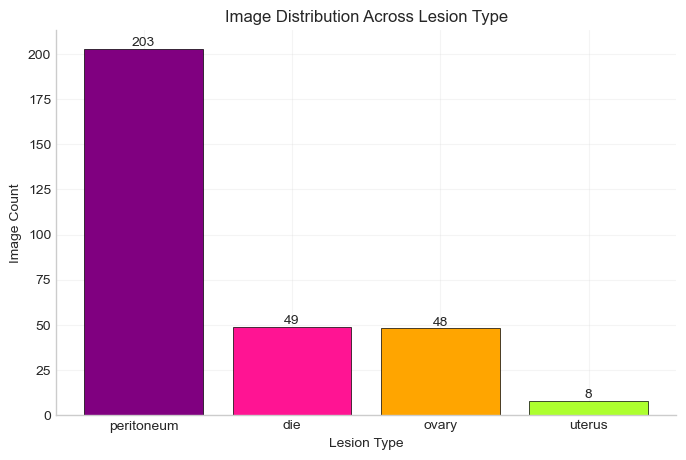

In [22]:
# Sort lesion categories by descending frequency
lesion_image_freq_sorted = pd.Series(lesion_image_freq).sort_values(ascending = False)

lesion_types = lesion_image_freq_sorted.index
image_counts = lesion_image_freq_sorted.values

bars = plt.bar(lesion_types, 
               image_counts, 
               color = bar_colors,
               edgecolor = "black",
               linewidth = 0.5)

plt.bar_label(bars)
plt.xlabel("Lesion Type")
plt.ylabel("Image Count")
plt.title("Image Distribution Across Lesion Type")

plt.show()

Peritoneal lesions account for the majority of annotations (402 annotations across 203 images), whereas uterine lesions are comparatively underrepresented (14 annotations across 8 images).
Overall, the dataset exhibits an uneven distribution of lesion categories at both the annotation and image levels.

#### 1.1.5 Annotation Density Per Image
Summarize the number of annotations associated with each image and the maximum annotation density observed for each lesion class.

In [23]:
annotation_counts_per_image = Counter(
    len(ann_list) for ann_list in annotations_by_parent.values())

sorted_ann_keys = sorted(annotation_counts_per_image.keys())
ann_density_counts = [annotation_counts_per_image[k] for k in sorted_ann_keys]
annotation_counts_per_image_df = pd.DataFrame({
    "# of Annotations per Image": sorted_ann_keys,
    "# of Images": ann_density_counts})
annotation_counts_per_image_df

,# of Annotations per Image,# of Images
0,1,188
1,2,63
2,3,31
3,4,6
4,5,4
5,6,5
6,7,2
7,8,2
8,9,1


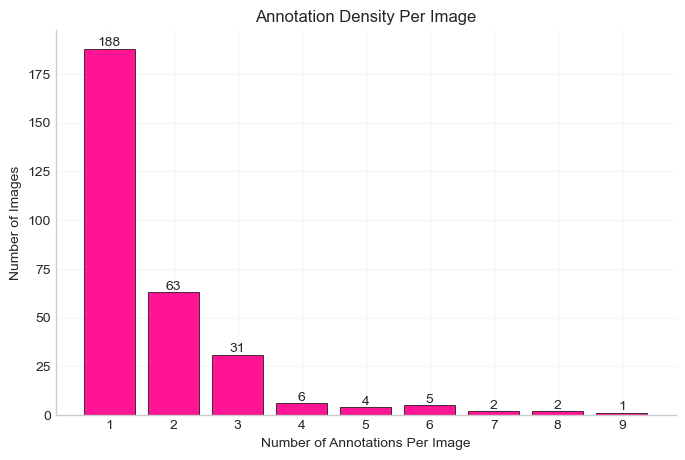

In [24]:
bars = plt.bar(sorted_ann_keys, 
               ann_density_counts, 
               color = "deeppink",
               edgecolor = "black",
               linewidth = 0.5)

plt.xticks(sorted_ann_keys)
plt.bar_label(bars)
plt.xlabel("Number of Annotations Per Image")
plt.ylabel("Number of Images")
plt.title("Annotation Density Per Image")

plt.show()

Most images have a low annotation density, with the majority containing 1 annotation (188 images), followed by 2 (63 images) and 3 (31 images). Beyond three, 
the frequency decreases substantially, indicating that images containing more than three annotations are relatively uncommon in the dataset.

In [25]:
annotation_counts_per_lesion_type = defaultdict(list)


for annotation_parent, ann_list in annotations_by_parent.items():
    density = len(ann_list)
    lesion_types = lesion_types_by_group[annotation_parent]
    for lesion in lesion_types:
        annotation_counts_per_lesion_type[lesion].append(density)

annotation_counts_per_lesion_type_df = pd.DataFrame({
    "Label": ["peritoneum", "die", "ovary", "uterus"],
    "Max Anns per Image": [
        max(annotation_counts_per_lesion_type["peritoneum"]),
        max(annotation_counts_per_lesion_type["die"]),
        max(annotation_counts_per_lesion_type["ovary"]),
        max(annotation_counts_per_lesion_type["uterus"])]})
annotation_counts_per_lesion_type_df

,Label,Max Anns per Image
0,peritoneum,9
1,die,3
2,ovary,2
3,uterus,3


The maximum number of annotations observed for a single image was summarized per lesion class. The peritoneum class had the highest annotation density, with a maximum of 9 annotations per image, whereas the ovary, die, and uterus classes had a maximum of 2 or 3 annotations.

### 1.2 Dataset Integrity and Annotation Validation

#### 1.2.1 Image File Integrity
Verify that all image files are accessible and structurally intact using Pillow's Image.verify().

In [26]:
inaccessible_images = []
for image in total_images:
    try:
        with Image.open(image) as img:
            img.verify()
    except Exception:
        inaccessible_images.append(image)
        
print("Inaccessible Images:", len(inaccessible_images))

Inaccessible Images: 0


#### 1.2.2 Annotation File Integrity
Verify that all annotation files are accessible and structurally intact.

In [27]:
inaccessible_annotations = []
for ann in pathology_annotations:
    try:
        with Image.open(ann) as img:
            img.verify()
    except Exception:
        inaccessible_annotations.append(ann)

print("Inaccessible Annotations:", len(inaccessible_annotations))

Inaccessible Annotations: 0


#### 1.2.3 Exact Duplicate Image Detection (SHA-256 Hashing)
Identify exact duplicate images within the dataset using SHA-256 hashing.

SHA-256 hashing generates a 256-bit (64-character hexadecimal) hash value for each image, where images with identical pixel data produce the same hash. 

In [28]:
no_pathology_hashes = defaultdict(list)
for img_path in no_pathology_images:
    img = np.array(Image.open(img_path).convert("RGB"))
    img_hash = hashlib.sha256(img.tobytes()).hexdigest()
    no_pathology_hashes[img_hash].append(img_path)

no_pathology_duplicates = {}
for img_hash, paths in no_pathology_hashes.items():
    if len(paths) > 1:
        no_pathology_duplicates[img_hash] = paths
        
total_no_pathology_duplicates = 0
for paths in no_pathology_duplicates.values():
    total_no_pathology_duplicates += len(paths)

In [29]:
pathology_hashes = defaultdict(list)
for img_path in pathology_images:
    img = np.array(Image.open(img_path).convert("RGB"))
    img_hash = hashlib.sha256(img.tobytes()).hexdigest()
    pathology_hashes[img_hash].append(img_path)

pathology_duplicates = {}
for img_hash, paths in pathology_hashes.items():
    if len(paths) > 1:
        pathology_duplicates[img_hash] = paths

total_pathology_duplicates = 0
for paths in pathology_duplicates.values():
    total_pathology_duplicates += len(paths)

In [30]:
duplicate_summary = pd.DataFrame({
    "Group": ["No Pathology", "Pathology"],
    "Duplicate Images": [total_no_pathology_duplicates, total_pathology_duplicates],
    "Total Images": [len(no_pathology_images), len(pathology_images)]})

duplicate_summary["Duplicate Percentage (%)"] = (duplicate_summary["Duplicate Images"] / duplicate_summary["Total Images"] * 100).round(3)

duplicate_summary

,Group,Duplicate Images,Total Images,Duplicate Percentage (%)
0,No Pathology,648,13438,4.822
1,Pathology,342,12244,2.793


Within the no_pathology group, 648 duplicate images were identified, representing 4.822% of its images. Within the pathology group, 342 duplicate images were identified, representing 2.793% of its images. These results demonstrate the presence of exact duplicates in both image groups, with a higher proportion in the no_pathology images. 

In [31]:
# Examples of 'no_pathology' exact duplicate image pairs
duplicate_pairs = random.sample(list(no_pathology_duplicates.values()), 3)

for i, paths in enumerate(duplicate_pairs, 1):
    print(f"Duplicate Pair {i}:")
    print(f"{Path(paths[0]).parent.name}/{Path(paths[0]).stem}  |  "
          f"{Path(paths[1]).parent.name}/{Path(paths[1]).stem}")

Duplicate Pair 1:
v_4761_s_0-354/f_248  |  v_4770_s_30-361/f_248
Duplicate Pair 2:
v_4761_s_0-354/f_142  |  v_4770_s_30-361/f_142
Duplicate Pair 3:
v_4761_s_0-354/f_108  |  v_4770_s_30-361/f_108


In [32]:
# Examples of 'pathology' exact duplicate image pairs
duplicate_pairs = random.sample(list(pathology_duplicates.values()), 3)

for i, paths in enumerate(duplicate_pairs, 1):
    print(f"Duplicate Pair {i}:")
    print(f"{Path(paths[0]).parent.name}/{Path(paths[0]).stem}  |  "
          f"{Path(paths[1]).parent.name}/{Path(paths[1]).stem}")

Duplicate Pair 1:
v_2638_s_150-232/f_211  |  v_2662_s_143-230/f_211
Duplicate Pair 2:
v_2617_s_177-275/f_253  |  v_2641_s_161-265/f_253
Duplicate Pair 3:
v_2638_s_150-232/f_168  |  v_2662_s_143-230/f_168


Duplicate images were observed across different parent sequence directories, while the frame identifier (fID) for each image file was the same. This indicates that the dataset contains repeated content beyond individual frame sequences, resulting in duplicate observations. The duplicate copies are removed in Section [1.3.1 Removal of Exact Duplicates](#1.3.1-Removal-of-Exact-Duplicates) to prevent repeated observations of the same image from affecting subsequent analyses.   

#### 1.2.4 Annotation Pixel Value Inspection
Inspect the unique pixel values within annotations to verify that masks contain only the expected values.

In [33]:
image = Image.open(pathology_annotations[0])
image_array = np.array(image)
print(f"Unique pixel values: {np.unique(image_array)}")

Unique pixel values: [  0 255]


Annotation masks contain only pixel values of 0 and 255, indicating a binary mask where 0 represents the background and 255 represents the annotated region.

#### 1.2.5 Annotation Label Consistency
Verify that annotation labels correspond to the four expected lesion categories: peritoneum, ovary, uterus, and die.

In [34]:
# Confirm four lesion categories: peritoneum, die, ovary, uterus
unique_lesion_labels = set()
for ann_list in annotations_by_parent.values():
    for ann in ann_list:
        label = ann.stem.split('_')[0]
        unique_lesion_labels.add(label)

print(unique_lesion_labels)

{'ovary', 'die', 'peritoneum', 'uterus'}


#### 1.2.6 Zero-Size Annotations
Identify any empty (zero-pixel) annotation files.

In [35]:
zero_size_annotations = []

for ann in pathology_annotations:
    size = np.count_nonzero(np.array(Image.open(ann)))
    if size == 0:
        zero_size_annotations.append(ann)
print(f"Total zero-size annotations: {len(zero_size_annotations)}")

Total zero-size annotations: 2


#### 1.2.7 Zero-Size Annotation Context Analysis
Investigate the context of zero-pixel annotations to determine whether they occur in isolation or alongside other annotation files. 

In [36]:
for zero_ann in zero_size_annotations:
    annotation_group = zero_ann.parent.relative_to(Path("GLENDA_v1.0/DS/pathology/annotations"))
    print(f"\nAnnotation Group: {annotation_group}")
    
    for ann in annotations_by_parent[zero_ann.parent]:
        size = np.count_nonzero(np.array(Image.open(ann)))
        print(f" {ann.name}: {size} pixels")


Annotation Group: v_3119_s_185-278\f_185
 peritoneum_a_692.png: 1196 pixels
 peritoneum_a_693.png: 0 pixels
 peritoneum_a_694.png: 931 pixels
 peritoneum_a_695.png: 197 pixels
 peritoneum_a_696.png: 943 pixels
 peritoneum_a_697.png: 8650 pixels
 peritoneum_a_698.png: 425 pixels
 peritoneum_a_699.png: 9329 pixels

Annotation Group: v_3119_s_1311-1399\f_1311
 peritoneum_a_700.png: 1005 pixels
 peritoneum_a_701.png: 1303 pixels
 peritoneum_a_702.png: 0 pixels
 peritoneum_a_703.png: 820 pixels
 peritoneum_a_704.png: 552 pixels
 peritoneum_a_705.png: 6422 pixels
 peritoneum_a_706.png: 667 pixels
 peritoneum_a_707.png: 4853 pixels
 peritoneum_a_708.png: 659 pixels


Empty pixel-level annotations were found to co-occur with non-empty annotations within the same annotation group rather than occurring independently. Therefore, these zero-size annotations do not appear to represent images entirely lacking lesion annotations. The purpose of these empty annotation files cannot be determined from available information. Given that they do not define a valid lesion region, the two zero-size annotations were treated as invalid and are removed in Section [1.3.2 Removal of Zero-Size Annotations](#1.3.2-Removal-of-Zero-Size-Annotations).

### 1.3 Data Cleaning

#### 1.3.1 Removal of Exact Duplicates
Remove exact duplicate images detected using SHA-256 hashing in Section [1.2.3 Exact Duplicate Image Detection (SHA-256 Hashing)](#1.2.3-Exact-Duplicate-Image-Detection-(SHA-256-Hashing)) and store the cleaned image lists in `no_pathology_images_clean` and `pathology_images_clean`.

In [37]:
# Remove exact duplicate images from both image sets
no_pathology_images_clean = no_pathology_images.copy()

for paths in no_pathology_duplicates.values():
    for path in paths[1:]:
        no_pathology_images_clean.remove(path)

pathology_images_clean = pathology_images.copy()

for paths in pathology_duplicates.values():
    for path in paths[1:]:
        pathology_images_clean.remove(path)

#### 1.3.2 Removal of Zero-Size Annotations
Remove the two zero-size (empty) annotations found in Section [1.2.6 Zero-Size Annotations](#1.2.6-Zero-Size-Annotations) and store the cleaned annotation file list in `pathology_annotations_clean`. Regroup the remaining annotation files by their parent directories and store the groupings in the dictionary `annotations_by_parent_clean`.

In [38]:
# Remove zero-size annotations
pathology_annotations_clean = pathology_annotations.copy()
for path in zero_size_annotations:
    pathology_annotations_clean.remove(path)

annotations_by_parent_clean = defaultdict(list)
for ann in pathology_annotations_clean:
    annotation_parent = ann.parent
    annotations_by_parent_clean[annotation_parent].append(ann)

#### 1.3.3 Dataset Counts After Cleaning
Display image and annotation counts before and after data cleaning. 

In [39]:
total_images_clean = no_pathology_images_clean + pathology_images_clean
clean_image_counts_df = pd.DataFrame({
    "Dataset Component": ["no_pathology", "pathology", "Total"], 
    "Original Count": [len(no_pathology_images), len(pathology_images), len(total_images)],
    "Images Removed": [len(no_pathology_images) - len(no_pathology_images_clean),
                       len(pathology_images) - len(pathology_images_clean),
                       len(total_images) - len(total_images_clean)],
    "% Removed": [(len(no_pathology_images) - len(no_pathology_images_clean)) / len(no_pathology_images) * 100,
                  (len(pathology_images) - len(pathology_images_clean)) / len(pathology_images) * 100,
                 (len(total_images) - len(total_images_clean)) / len(total_images) * 100],
    "Count After Cleaning": [len(no_pathology_images_clean), len(pathology_images_clean), len(total_images_clean)]})
clean_image_counts_df["% Removed"] = clean_image_counts_df["% Removed"].round(3)
clean_image_counts_df

,Dataset Component,Original Count,Images Removed,% Removed,Count After Cleaning
0,no_pathology,13438,324,2.411,13114
1,pathology,12244,171,1.397,12073
2,Total,25682,495,1.927,25187


In [40]:
clean_ann_counts_df = pd.DataFrame({
    "Dataset Component": ["Annotation Files"], 
    "Original Count": [len(pathology_annotations)],
    "Annotations Removed": [len(pathology_annotations) - len(pathology_annotations_clean)],
    "% Removed": [(len(pathology_annotations) - len(pathology_annotations_clean)) / len(pathology_annotations) * 100],
    "Count After Cleaning": [len(pathology_annotations_clean)]})
clean_ann_counts_df["% Removed"] = clean_ann_counts_df["% Removed"].round(3)
clean_ann_counts_df

,Dataset Component,Original Count,Annotations Removed,% Removed,Count After Cleaning
0,Annotation Files,520,2,0.385,518


[↑ Back to Table of Contents](#Table-of-Contents)

## 2. Lesion Annotation Characteristics
Characterize annotations through size statistics, area distributions, outlier analysis, and spatial patterns.

### Annotation Feature Extraction
Extract annotation properties using the `extract_annotation_features()` function and store features in the `all_features_df` DataFrame. 

In [41]:
all_annotation_features = []
for annotation_parent, ann_list in annotations_by_parent_clean.items():
    for ann in ann_list:
        features = extract_annotation_features(ann)

        features["annotation_parent"] = annotation_parent
        all_annotation_features.append(features)
        
all_features_df = pd.DataFrame(all_annotation_features)
all_features_df.head(5)

,area,x,y,lesion_type,annotation_path,annotation_parent
0,8438,344.822114,78.797938,peritoneum,GLENDA_v1.0\DS\pathology\annotations\v_998_s_8...,GLENDA_v1.0\DS\pathology\annotations\v_998_s_8...
1,10914,338.562763,89.140553,peritoneum,GLENDA_v1.0\DS\pathology\annotations\v_997_s_1...,GLENDA_v1.0\DS\pathology\annotations\v_997_s_1...
2,11023,349.351628,122.767940,die,GLENDA_v1.0\DS\pathology\annotations\v_993_s_7...,GLENDA_v1.0\DS\pathology\annotations\v_993_s_7...
3,1141,248.577564,39.739702,peritoneum,GLENDA_v1.0\DS\pathology\annotations\v_9755_s_...,GLENDA_v1.0\DS\pathology\annotations\v_9755_s_...
4,1391,251.459382,89.849029,peritoneum,GLENDA_v1.0\DS\pathology\annotations\v_9755_s_...,GLENDA_v1.0\DS\pathology\annotations\v_9755_s_...


### 2.1 Annotation Size Statistics

In [42]:
# Compute annotation size statistics (avg, median, sd, min, max) for annotation files
annotation_stats = all_features_df.groupby("lesion_type")["area"].agg(
    avg="mean",
    median="median",
    sd="std",
    min="min",
    max="max")
print(annotation_stats.round(3)) 

                   avg   median         sd   min     max
lesion_type                                             
die          21365.264  15315.0  19100.378  3233   95668
ovary        31176.392  20989.0  27374.257   761  102368
peritoneum    5824.782   2336.5  10484.846   197   95446
uterus        7696.000   4409.5  10311.471   613   40349


Annotation areas differ across lesion types, with the ovary and die annotations having the largest average areas, while peritoneum and uterus annotations are smaller on average. Within each lesion type, annotation areas also show considerable variability, as reflected by the standard deviations and ranges. For all lesion types, the mean annotation area is greater than the median, indicating right-skewed distributions in which a smaller number of larger annotations increase the mean.

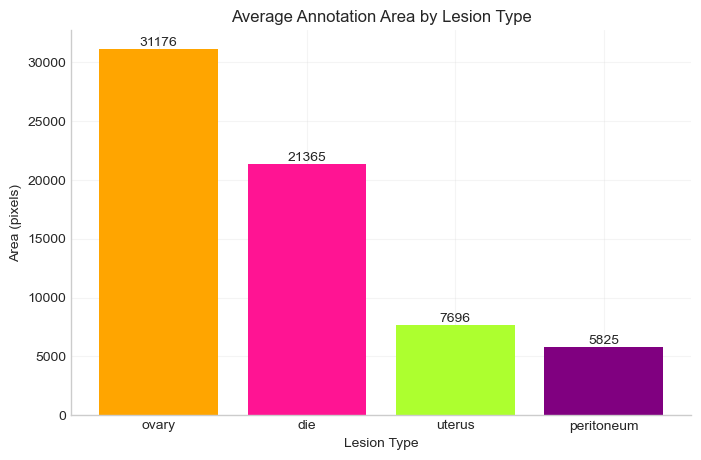

In [43]:
annotation_avg_sorted = annotation_stats.sort_values("avg", ascending = False)

bar_colors = [lesion_colors[lesion] for lesion in annotation_avg_sorted.index]

bars = plt.bar(
    annotation_avg_sorted.index,
    annotation_avg_sorted["avg"],
    color = bar_colors
)
plt.bar_label(bars, fmt="%.0f")
plt.title("Average Annotation Area by Lesion Type")
plt.ylabel("Area (pixels)")
plt.xlabel("Lesion Type")

plt.show()

### 2.2 Annotation Size Distribution

#### 2.2.1 Overall Distribution of Annotation Areas
Visualize the overall distribution of annotation areas to assess the skewness and spread of annotation sizes across all lesion classes. 

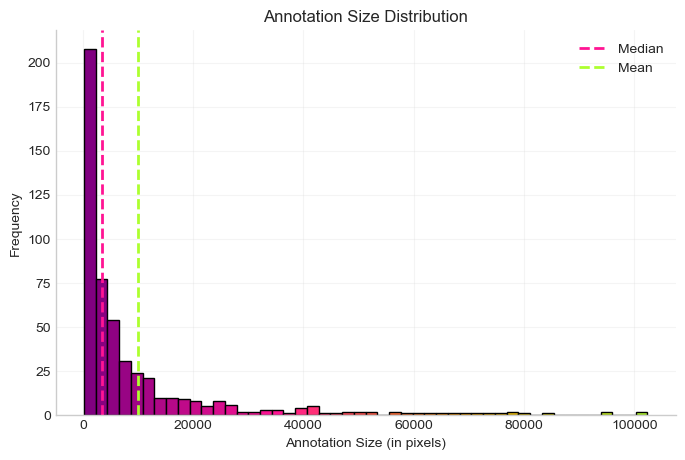

In [44]:
all_annotation_sizes = all_features_df["area"]

plt.figure()

counts, bins, patches = plt.hist(all_annotation_sizes, bins="fd", edgecolor="black")
norm = plt.Normalize(vmin=min(all_annotation_sizes), vmax=max(all_annotation_sizes))
for patch, left_edge in zip(patches, bins[:-1]):
        patch.set_facecolor(cmap(norm(left_edge)))
    
median_size = np.median(all_annotation_sizes)
plt.axvline(median_size, color='deeppink', linestyle='--', linewidth=2, label='Median')

mean_size = np.mean(all_annotation_sizes)

plt.axvline(mean_size, color='greenyellow', linestyle='--', linewidth=2, label='Mean')

plt.title("Annotation Size Distribution")
plt.xlabel("Annotation Size (in pixels)")
plt.ylabel("Frequency")
plt.legend()

plt.show()

The distribution of annotation areas is strongly right-skewed, with most areas concentrated toward the lower end of the range. This indicates that the majority of annotations are relatively small, while fewer represent much larger annotated regions, resulting in a wide range of observed annotation sizes. One possible explanation is the dataset's composition, as peritoneum annotations are both highly prevalent and tend to occupy smaller annotation areas on average. However, this pattern could also be influenced by factors such as annotation practices and anatomical differences.

#### 2.2.2 Annotation Size Distribution by Lesion Type
Compare annotation area distributions by lesion type using box plots to evaluate differences in variability and outlier patterns. 

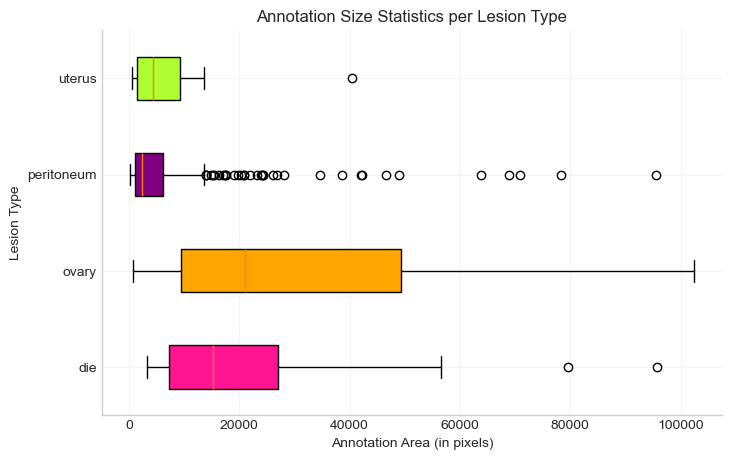

In [45]:
lesion_types = sorted(all_features_df["lesion_type"].unique())
lesion_sizes = [all_features_df.loc[all_features_df["lesion_type"] == lesion_type, "area"] for lesion_type in lesion_types]

box_colors = [lesion_colors[lesion] for lesion in lesion_types]

# Boxplot of annotation areas (pixel counts), grouped by lesion type
bplot = plt.boxplot(lesion_sizes, tick_labels = lesion_types, patch_artist = True, vert = False)

# Apply consistent lesion color scheme defined earlier in analysis
for patch, color in zip(bplot['boxes'], box_colors):
    patch.set_facecolor(color)

plt.title("Annotation Size Statistics per Lesion Type")
plt.xlabel("Annotation Area (in pixels)")
plt.ylabel("Lesion Type")

plt.show()

The boxplots reveal clear differences in the distributions of annotation areas across lesion types. The ovary class displays the widest interquartile range, indicating greater variability in annotation sizes within the central 50% of the data. In contrast, the peritoneum and uterus classes have narrower IQRs, indicating more concentrated distributions. 

Peritoneum contains noticeably more outliers than the other groups. The ovary class has no identified outliers, while die and uterus have 2 and 1 outliers, respectively. All identified outliers lie beyond the right whisker, indicating that they represent unusually large annotation areas relative to their respective distributions. 

Together, these findings indicate that the greater variability in ovary annotations is reflected primarily in the dispersion within the main distribution, whereas the peritoneum distribution has relatively limited central dispersion but more extreme upper-tail observations. The larger number of peritoneum annotations may also contribute to the greater number of observed outliers, since larger sample sizes provide more opportunities for extreme observations to occur.  

### 2.3 Annotation Outlier Analysis
Evaluate the proportion of annotation area outliers for each lesion type and compare peritoneum outliers against non-outlier areas within the class.

#### 2.3.1 Outlier Proportions by Lesion Type
Summarize the proportion of outliers for each lesion type, accounting for differences in class size.

In [46]:
outlier_bounds = {}
outliers_by_type = {}
for lesion_type in all_features_df["lesion_type"].unique():
    df_type = all_features_df[all_features_df["lesion_type"] == lesion_type]
    sizes = df_type["area"].to_numpy()
    
    q1 = df_type["area"].quantile(0.25)
    q3 = df_type["area"].quantile(0.75)
    iqr = q3 - q1
    
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outlier_bounds[lesion_type] = (lower, upper)
    outliers_by_type[lesion_type] = df_type[(df_type["area"] < lower) | (df_type["area"] > upper)]

In [47]:
outlier_summary_rows = []
for lesion_type, outliers_df in outliers_by_type.items():
    df_type = all_features_df[all_features_df["lesion_type"] == lesion_type]
    outlier_summary_rows.append({  
        "lesion_type": lesion_type,
        "outlier_count": len(outliers_df),
        "total_count": len(df_type),
        "outlier_percent": round((len(outliers_df) / len(df_type)) * 100, 3)})

total_outliers = sum(row["outlier_count"] for row in outlier_summary_rows)
total_count = sum(row["total_count"] for row in outlier_summary_rows)

outlier_summary_rows.append({
    "lesion_type": "Total",
    "outlier_count": total_outliers,
    "total_count": total_count,
    "outlier_percent": round((total_outliers / total_count) * 100, 3)
})

outlier_summary_df = pd.DataFrame(outlier_summary_rows)

In [48]:
outlier_summary_df

,lesion_type,outlier_count,total_count,outlier_percent
0,peritoneum,36,400,9.000
1,die,2,53,3.774
2,uterus,1,14,7.143
3,ovary,0,51,0.000
4,Total,39,518,7.529


Differences in the number of annotations belonging to each lesion class are important to consider when evaluating the relative prevalence of outliers. Specifically, the uterus class has only one outlier, but because it contains 14 annotations, that single outlier accounts for 7.143% of its annotations. In comparison, the peritoneum class has 36 outliers, but they account for 9.000% of its 400 annotations. As a result, despite the large difference in the number of detected outliers, the two lesion classes have comparable outlier proportions. 

#### 2.3.2 Peritoneum Annotation Area Outliers
Visualize and compare peritoneum annotation area outliers with non-outlier annotations. 

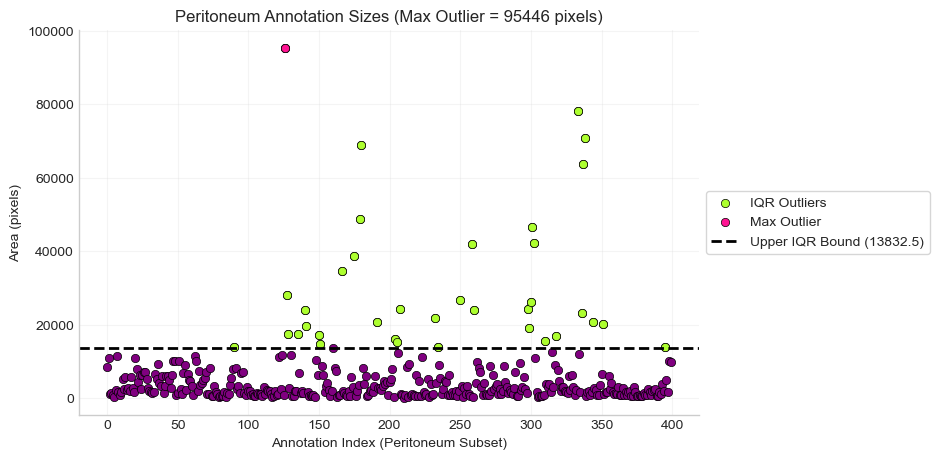

In [49]:
peritoneum_df = all_features_df[all_features_df["lesion_type"] == "peritoneum"].reset_index(drop = True)
lower, upper = outlier_bounds["peritoneum"]
outlier_positions = peritoneum_df.index[(peritoneum_df["area"] < lower) | (peritoneum_df["area"] > upper)]

plt.figure()

# Plot all peritoneum annotations for comparison 
plt.scatter(range(len(peritoneum_df)), peritoneum_df["area"], color = "purple", edgecolor = "black", linewidth = 0.5)

# Highlight IQR outlier annotations
plt.scatter(outlier_positions, peritoneum_df.loc[outlier_positions, "area"], color = "greenyellow", edgecolor = "black", linewidth = 0.5, label = "IQR Outliers")

max_index = peritoneum_df["area"].idxmax()
max_val = peritoneum_df.loc[max_index, "area"]

# Highlight the maximum outlier
plt.scatter(max_index, max_val, color = "deeppink", edgecolor = "black", linewidth = 0.5, label = "Max Outlier")

# Upper IQR threshold line for reference
plt.axhline(y = upper, color = "black", linestyle = "--", linewidth = 2, label = f"Upper IQR Bound ({upper})")

plt.title(f"Peritoneum Annotation Sizes (Max Outlier = {max_val} pixels)")
plt.xlabel("Annotation Index (Peritoneum Subset)")
plt.ylabel("Area (pixels)")
plt.legend(frameon = True, loc = "center left", bbox_to_anchor = (1, 0.5))
plt.show()

Several peritoneum annotation areas fall near the upper IQR boundary, placing them near the threshold separating outlier and non-outlier values. Although some outliers are less clearly distinguishable, many lie meaningfully beyond the upper boundary. The maximum outlier is particularly extreme, with an area considerably larger than the rest of the data, including many of the other identified outliers.

### 2.4 Spatial Distribution of Lesions
Visualize and assess patterns of lesion spatial distribution using centroid scatterplots and a heatmap.

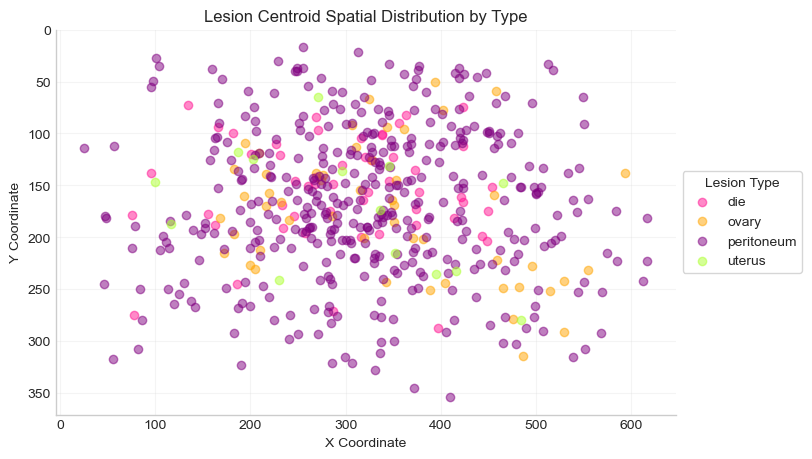

In [50]:
# Visualize the scatter plot distribution of lesion centroids
for lesion_type, df in all_features_df.groupby("lesion_type"):
    plt.scatter(df["x"], df["y"], alpha = 0.5, color = lesion_colors[lesion_type], label = lesion_type)
plt.gca().invert_yaxis()   
plt.title("Lesion Centroid Spatial Distribution by Type")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.legend(title="Lesion Type", frameon = True, loc = "center left", bbox_to_anchor = (1, 0.5))

plt.show()

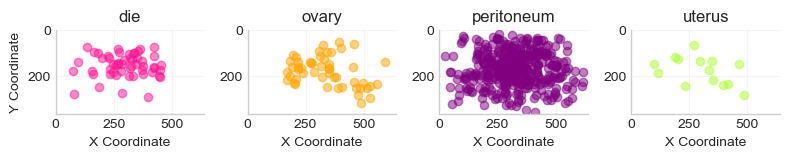

In [51]:
# Visualize lesion centroid distributions separately by type
fig, axes = plt.subplots(1, 4)
lesion_types = sorted(all_features_df["lesion_type"].unique())
for i, lesion_type in enumerate(lesion_types):
    df = all_features_df[all_features_df["lesion_type"] == lesion_type]
    axes[i].scatter(df["x"], df["y"], alpha = 0.5, color = lesion_colors[lesion_type])

    axes[i].set_title(lesion_type)
    axes[i].invert_yaxis()
    axes[i].set_xlim(0, 640)
    axes[i].set_ylim(360, 0)
    axes[i].set_xlabel("X Coordinate")
    axes[i].set_aspect("equal")
axes[0].set_ylabel("Y Coordinate")

plt.tight_layout()
plt.show()

Analysis of the annotation centroid spatial distribution for each lesion type revealed specific patterns:
* die: centroids show a relatively wide distribution throughout the central portion of the image.
* ovary: centroids form a rounded cluster, possibly reflecting the anatomical shape of the ovaries.
* peritoneum: centroids are concentrated towards the center but also spread widely in all directions.
* uterus: no clear pattern is observed, which may be due to the small sample size or anatomical variability of lesion locations along the outer surface of the uterus. 

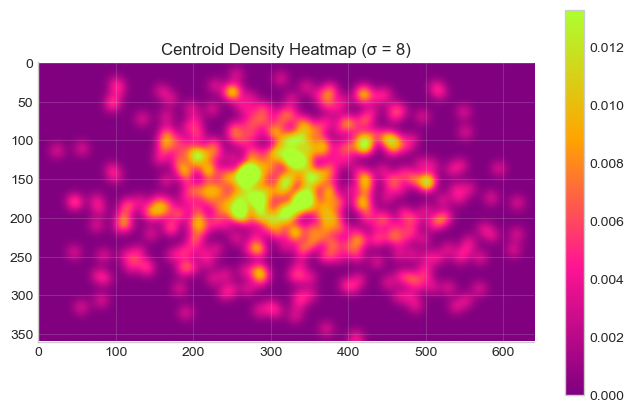

In [52]:
centroids_df = all_features_df.dropna(subset=["x", "y"])

heatmap = np.zeros((360, 640))

for index, row in centroids_df.iterrows():
    x = row["x"]
    y = row["y"]
    heatmap[int(y), int(x)] += 1
sigma = 8
heatmap_smooth = gaussian_filter(heatmap, sigma= sigma)
plt.imshow(heatmap_smooth, cmap=cmap, vmax=np.percentile(heatmap_smooth, 99))
plt.colorbar()
plt.title(f"Centroid Density Heatmap (σ = {sigma})")
plt.show()

Lesion centroids demonstrate central tendency, with most annotations concentrated within the central field of view. The remaining annotations are distributed throughout the surrounding regions of the image, but at lower densities. 

[↑ Back to Table of Contents](#Table-of-Contents)

## 3. Image Quality and Color Metrics
Compute and analyze image quality metrics (brightness, contrast, sharpness) and color metrics (RGB channel distributions) to provide numerical representations of the dataset's visual characteristics.

### 3.1 Brightness Analysis
Analyze image brightness using the average grayscale pixel intensity and assess its distribution across the no_pathology and pathology groups. 

In [53]:
no_pathology_brightness = []
for img_path in no_pathology_images_clean:
    img = np.array(Image.open(img_path).convert("L")).astype(np.float32) / 255.0
    no_pathology_brightness.append( {
    "image_id": img_path.stem,
    "img_path": img_path,
    "mean_intensity": img.mean()})
no_pathology_brightness_df = pd.DataFrame(no_pathology_brightness)

In [54]:
pathology_brightness = []
for img_path in pathology_images_clean:
    img = np.array(Image.open(img_path).convert("L")).astype(np.float32) / 255.0
    pathology_brightness.append({
    "image_id": img_path.stem,
    "img_path": img_path,
    "mean_intensity": img.mean()})
pathology_brightness_df = pd.DataFrame(pathology_brightness)

In [55]:
compare_brightness_df = pd.DataFrame({
    "No Pathology": no_pathology_brightness_df["mean_intensity"],
    "Pathology": pathology_brightness_df["mean_intensity"]
}).describe()
compare_brightness_df.round(3)

,No Pathology,Pathology
count,13114.000,12073.000
mean,0.360,0.367
std,0.037,0.036
min,0.153,0.190
25%,0.335,0.344
50%,0.359,0.363
75%,0.379,0.389
max,0.780,0.787


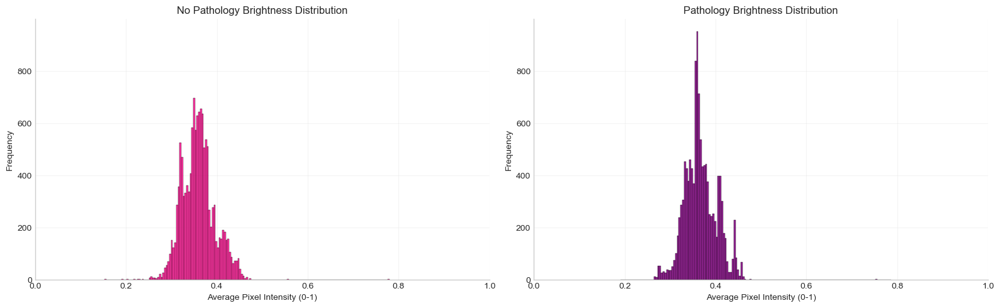

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].hist(no_pathology_brightness_df["mean_intensity"], bins = "fd", color = "deeppink", edgecolor = "black", alpha = 0.85, linewidth = 0.3)
axes[0].set_title("No Pathology Brightness Distribution")
axes[0].set_xlim(0.0, 1.0)
axes[0].set_xlabel("Average Pixel Intensity (0-1)")
axes[0].set_ylabel("Frequency")

axes[1].hist(pathology_brightness_df["mean_intensity"], bins = "fd", color = "purple", edgecolor = "black", alpha = 0.85, linewidth = 0.3)
axes[1].set_title("Pathology Brightness Distribution")
axes[1].set_xlim(0.0, 1.0)
axes[1].set_xlabel("Average Pixel Intensity (0-1)")
axes[1].set_ylabel("Frequency")

max_y = max(axes[0].get_ylim()[1], axes[1].get_ylim()[1])

axes[0].set_ylim(0, max_y)
axes[1].set_ylim(0, max_y)

plt.tight_layout()
plt.show()

Grayscale pixel intensities were normalized to a range of 0 to 1, where 0 represents black and 1 represents white. Based on this scale, both no_pathology and pathology image groups exhibit relatively low brightness overall, with average normalized pixel intensities of 0.360 and 0.367, respectively. These intensity values may reflect the lighting conditions in gynecologic laparoscopic surgery. The similarity in both average pixel intensities and their variability suggests relatively consistent lighting across the dataset.

### 3.2 Contrast Analysis
Analyze image contrast using grayscale intensity variability, measured by the standard deviation and 95th-5th percentile intensity range. 

In [57]:
no_pathology_contrast = []
for img_path in no_pathology_images_clean:
    img = np.array(Image.open(img_path).convert("L")).astype(np.float32) / 255.0
    no_pathology_contrast.append({
    "image_id": img_path.stem,
    "img_path": img_path,
    "contrast_std": img.std(),
    "contrast_p95_p5": np.percentile(img, 95) - np.percentile(img, 5)})
no_pathology_contrast_df = pd.DataFrame(no_pathology_contrast) 

In [58]:
pathology_contrast = []
for img_path in pathology_images_clean:
    img = np.array(Image.open(img_path).convert("L")).astype(np.float32) / 255.0
    pathology_contrast.append({
    "image_id": img_path.stem,
    "img_path": img_path,
    "contrast_std": img.std(),
    "contrast_p95_p5": np.percentile(img, 95) - np.percentile(img, 5)})
pathology_contrast_df = pd.DataFrame(pathology_contrast) 

In [59]:
compare_contrast_std_df = pd.DataFrame({
    "No Pathology": no_pathology_contrast_df["contrast_std"],
    "Pathology": pathology_contrast_df["contrast_std"]
}).describe()
compare_contrast_std_df.round(3)

,No Pathology,Pathology
count,13114.000,12073.000
mean,0.138,0.143
std,0.029,0.031
min,0.062,0.072
25%,0.116,0.122
50%,0.134,0.139
75%,0.155,0.159
max,0.337,0.368


In [60]:
compare_contrast_p95_p5_df = pd.DataFrame({
    "No Pathology": no_pathology_contrast_df["contrast_p95_p5"],
    "Pathology": pathology_contrast_df["contrast_p95_p5"]
}).describe()
compare_contrast_p95_p5_df.round(3)

,No Pathology,Pathology
count,13114.000,12073.000
mean,0.437,0.458
std,0.102,0.106
min,0.165,0.227
25%,0.361,0.384
50%,0.416,0.443
75%,0.494,0.510
max,0.949,0.929


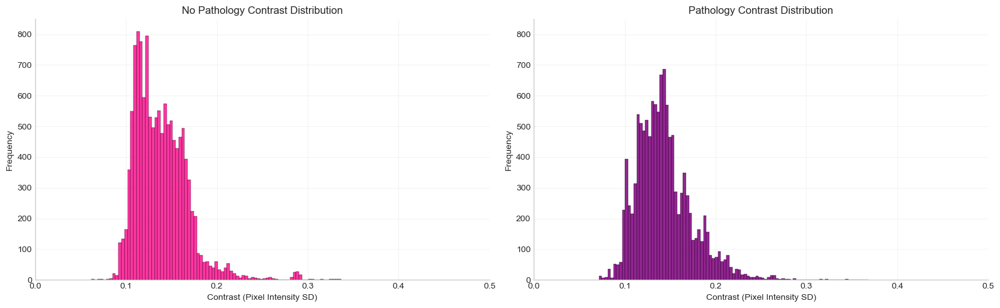

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].hist(no_pathology_contrast_df["contrast_std"], bins = "fd", color = "deeppink", edgecolor = "black", alpha = 0.85, linewidth = 0.3)
axes[0].set_title("No Pathology Contrast Distribution")
axes[0].set_xlim(0.0, 0.5)
axes[0].set_xlabel("Contrast (Pixel Intensity SD)")
axes[0].set_ylabel("Frequency")

axes[1].hist(pathology_contrast_df["contrast_std"], bins = "fd", color = "purple", edgecolor = "black", alpha = 0.85, linewidth = 0.3)
axes[1].set_title("Pathology Contrast Distribution")
axes[1].set_xlim(0.0, 0.5)
axes[1].set_xlabel("Contrast (Pixel Intensity SD)")
axes[1].set_ylabel("Frequency")


max_y = max(axes[0].get_ylim()[1], axes[1].get_ylim()[1])

axes[0].set_ylim(0, max_y)
axes[1].set_ylim(0, max_y)

plt.tight_layout()
plt.show()

Contrast was evaluated using two metrics: the standard deviation of pixel intensities, which captures overall variability, and the percentile-based intensity range (P95 - P5), which reduces the influence of extreme pixel values that may arise from localized bright or dark regions. Each metric produced similar contrast distributions for both the no_pathology and pathology groups. Minimal differences in mean, standard deviation, and range of these metrics suggest that image contrast is not a strong distinguishing characteristic between the two groups. 

### 3.3 Sharpness Analysis
Assess image sharpness using the Laplacian variance, a commonly used metric for blur detection that measures the variability of rapid changes in pixel intensity across an image.

In [62]:
no_pathology_sharpness = []
for img_path in no_pathology_images_clean:
    img = np.array(Image.open(img_path).convert("L")).astype(np.float32) / 255.0
    laplacian = laplace(img)
    no_pathology_sharpness.append({
    "image_id": img_path.stem,
    "img_path": img_path,
    "laplacian_variance": laplacian.var()})
no_pathology_sharpness_df = pd.DataFrame(no_pathology_sharpness) 

In [63]:
pathology_sharpness = []
for img_path in pathology_images_clean:
    img = np.array(Image.open(img_path).convert("L")).astype(np.float32) / 255.0
    laplacian = laplace(img)
    pathology_sharpness.append({
    "image_id": img_path.stem,
    "img_path": img_path,
    "laplacian_variance": laplacian.var()})
pathology_sharpness_df = pd.DataFrame(pathology_sharpness) 

In [64]:
compare_sharpness_df = pd.DataFrame({
    "No_Pathology": no_pathology_sharpness_df["laplacian_variance"],
    "Pathology": pathology_sharpness_df["laplacian_variance"]}).describe()
compare_sharpness_df.round(3)

,No_Pathology,Pathology
count,13114.000,12073.000
mean,0.004,0.004
std,0.002,0.002
min,0.000,0.000
25%,0.002,0.003
50%,0.004,0.004
75%,0.005,0.006
max,0.013,0.017


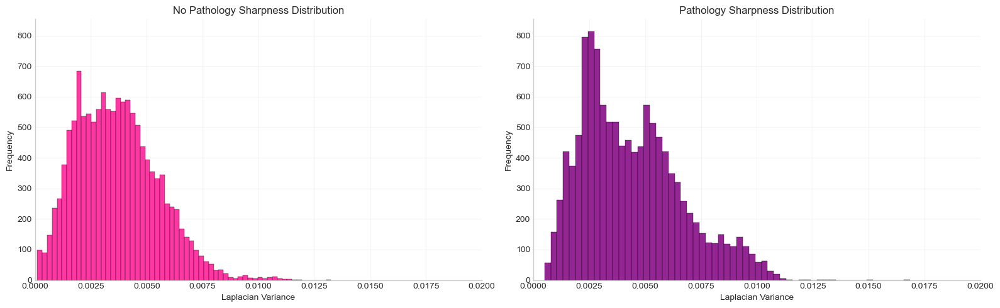

In [65]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].hist(no_pathology_sharpness_df["laplacian_variance"], bins = "fd", color = "deeppink", edgecolor = "black", alpha = 0.85, linewidth = 0.3)
axes[0].set_title("No Pathology Sharpness Distribution")
axes[0].set_xlim(0.0, 0.02)
axes[0].set_xlabel("Laplacian Variance")
axes[0].set_ylabel("Frequency")

axes[1].hist(pathology_sharpness_df["laplacian_variance"], bins = "fd", color = "purple", edgecolor = "black", alpha = 0.85, linewidth = 0.3)
axes[1].set_title("Pathology Sharpness Distribution")
axes[1].set_xlim(0.0, 0.02)
axes[1].set_xlabel("Laplacian Variance")
axes[1].set_ylabel("Frequency")

max_y = max(axes[0].get_ylim()[1], axes[1].get_ylim()[1])

axes[0].set_ylim(0, max_y)
axes[1].set_ylim(0, max_y)

plt.tight_layout()
plt.show()

Generally, higher Laplacian variance values indicate sharper image structure, with image sharpness interpreted relative to the distribution of values within the dataset. Both pathology and no_pathology image groups exhibited highly similar sharpness distributions, with identical mean Laplacian variance values (0.004) and standard deviations (0.002). The pathology group had a slightly higher maximum value compared to no_pathology images. However, the substantial overlap between the two distributions indicates that differences are minimal.

### 3.4 RGB Color Channel Intensity Analysis
Evaluate the average red, green, and blue channel intensity distributions across image groups.

In [66]:
no_pathology_rgb = []
for img_path in no_pathology_images_clean:
    img = np.array(Image.open(img_path).convert("RGB")).astype(np.float32) / 255.0
    no_pathology_rgb.append({
    "image_id": img_path.stem,
    "img_path": str(img_path),
    "avg_R": img[:, :, 0].mean(),
    "avg_G": img[:, :, 1].mean(),
    "avg_B": img[:, :, 2].mean()})
no_pathology_rgb_df = pd.DataFrame(no_pathology_rgb) 

In [67]:
pathology_rgb = []
for img_path in pathology_images_clean:
    img = np.array(Image.open(img_path).convert("RGB")).astype(np.float32) / 255.0
    pathology_rgb.append({
    "image_id": img_path.stem,
    "img_path": str(img_path),
    "avg_R": img[:, :, 0].mean(),
    "avg_G": img[:, :, 1].mean(),
    "avg_B": img[:, :, 2].mean()})
pathology_rgb_df = pd.DataFrame(pathology_rgb) 

In [68]:
compare_rgb_df = pd.DataFrame({
    "No_Pathology_R": no_pathology_rgb_df["avg_R"],
    "Pathology_R": pathology_rgb_df["avg_R"],
    "No_Pathology_G": no_pathology_rgb_df["avg_G"],
    "Pathology_G": pathology_rgb_df["avg_G"],
        "No_Pathology_B": no_pathology_rgb_df["avg_B"],
    "Pathology_B": pathology_rgb_df["avg_B"]}).describe()
compare_rgb_df.round(3)

,No_Pathology_R,Pathology_R,No_Pathology_G,Pathology_G,No_Pathology_B,Pathology_B
count,13114.000,12073.000,13114.000,12073.000,13114.000,12073.000
mean,0.491,0.497,0.307,0.314,0.284,0.297
std,0.034,0.036,0.043,0.041,0.050,0.054
min,0.230,0.249,0.131,0.162,0.016,0.162
25%,0.469,0.478,0.280,0.287,0.254,0.261
50%,0.493,0.500,0.309,0.308,0.283,0.295
75%,0.513,0.522,0.327,0.343,0.308,0.326
max,0.803,0.797,0.774,0.785,0.749,0.766


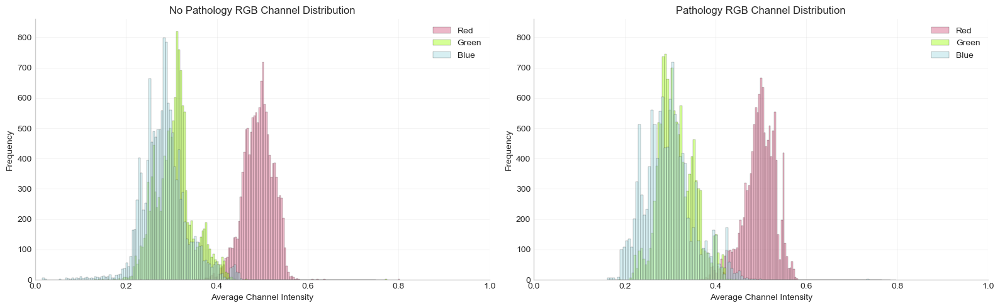

In [69]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].hist(no_pathology_rgb_df["avg_R"], bins = "fd", color = "palevioletred", edgecolor = "black", alpha = 0.5, linewidth = 0.3, label = "Red")
axes[0].hist(no_pathology_rgb_df["avg_G"], bins = "fd", color = "greenyellow", edgecolor = "black", alpha = 0.5, linewidth = 0.3, label = "Green")
axes[0].hist(no_pathology_rgb_df["avg_B"], bins = "fd", color = "powderblue", edgecolor = "black", alpha = 0.5, linewidth = 0.3, label = "Blue")
axes[0].set_title("No Pathology RGB Channel Distribution")
axes[0].set_xlim(0.0, 1.0)
axes[0].set_xlabel("Average Channel Intensity")
axes[0].set_ylabel("Frequency")
axes[0].legend()

axes[1].hist(pathology_rgb_df["avg_R"], bins = "fd", color = "palevioletred", edgecolor = "black", alpha = 0.5, linewidth = 0.3, label = "Red")
axes[1].hist(pathology_rgb_df["avg_G"], bins = "fd", color = "greenyellow", edgecolor = "black", alpha = 0.5, linewidth = 0.3, label = "Green")
axes[1].hist(pathology_rgb_df["avg_B"], bins = "fd", color = "powderblue", edgecolor = "black", alpha = 0.5, linewidth = 0.3, label = "Blue")
axes[1].set_title("Pathology RGB Channel Distribution")
axes[1].set_xlim(0.0, 1.0)
axes[1].set_xlabel("Average Channel Intensity")
axes[1].set_ylabel("Frequency")
axes[1].legend()

max_y = max(axes[0].get_ylim()[1], axes[1].get_ylim()[1])

axes[0].set_ylim(0, max_y)
axes[1].set_ylim(0, max_y)

plt.tight_layout()
plt.show()

Both image groups exhibited higher red channel intensities than the green and blue channels, with the red distribution shifted toward higher intensity values and showing minimal overlap with the other channels. This pattern may reflect the natural coloration of pelvic tissues, structures, and internal organs captured during laparoscopic surgical imaging. Mean channel intensities were highly similar between the two groups, with only minor increases observed in pathology images across all three channels. The comparable channel distributions suggest that overall color characteristics are not meaningfully influenced by pathology status within the dataset.  

[↑ Back to Table of Contents](#Table-of-Contents)

## 4. Dataset Visual Exploration and Annotation Visualization
Examine the GLENDA dataset visually through sample image inspection, randomized image group comparisons, lesion-annotation overlays, and multi-label cases with co-occurring lesion types.

### 4.1 Sample Image Visualization
Visualize images from each group and compare randomly selected samples to examine visual patterns and variability.

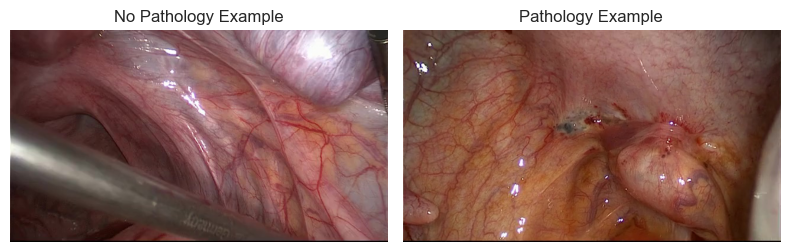

In [70]:
# Single sample visualization
fig, axes = plt.subplots(1, 2)
axes[0].imshow(plt.imread(no_pathology_images_clean[0]))
axes[0].set_title("No Pathology Example")
axes[0].axis("off")

axes[1].imshow(plt.imread(pathology_images_clean[0]))
axes[1].set_title("Pathology Example")
axes[1].axis("off")

plt.tight_layout()
plt.show()

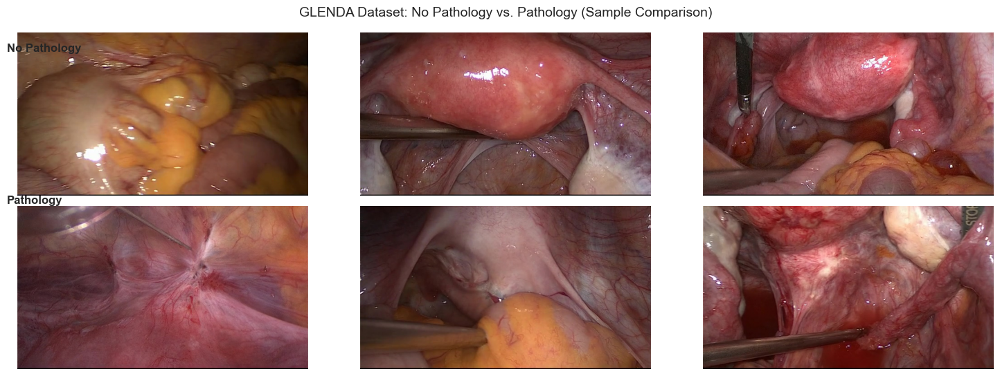

In [71]:
no_pathology_sample = random.sample(no_pathology_images_clean, 3)
pathology_sample = random.sample(pathology_images_clean, 3)

compare_image_groups(no_pathology_sample, pathology_sample, "No Pathology", "Pathology", title = "GLENDA Dataset: No Pathology vs. Pathology (Sample Comparison)")

- no_pathology images show expected tissue coloration and structure without any obvious pathological features.
- pathology images show localized regions (e.g., dark red or black areas), potentially corresponding to lesion presence.

### 4.2 Annotation Overlay Visualization
Visualize lesion annotations over their source images to verify annotation alignment and examine differences in lesion appearance and location between lesion classes.

In [72]:
# Randomly select a subset of ten annotated cases for visualization
selected_annotation_groups = random.sample(sorted(annotations_by_parent_clean.keys()), 4)

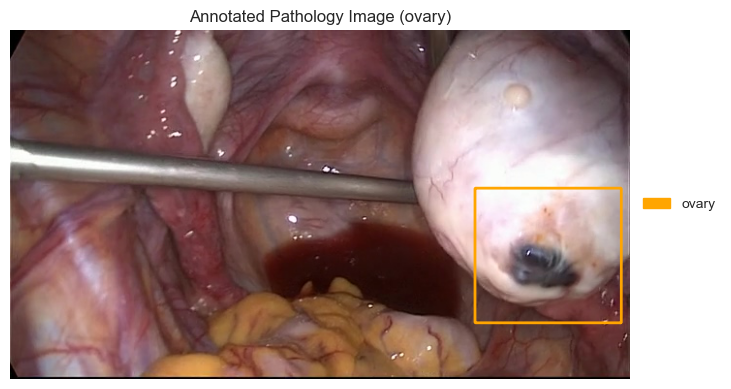

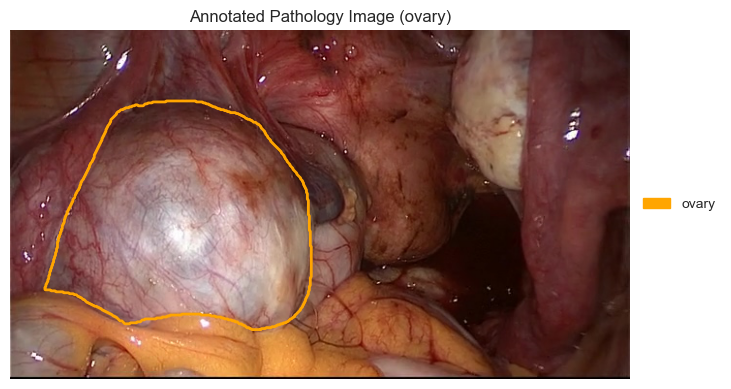

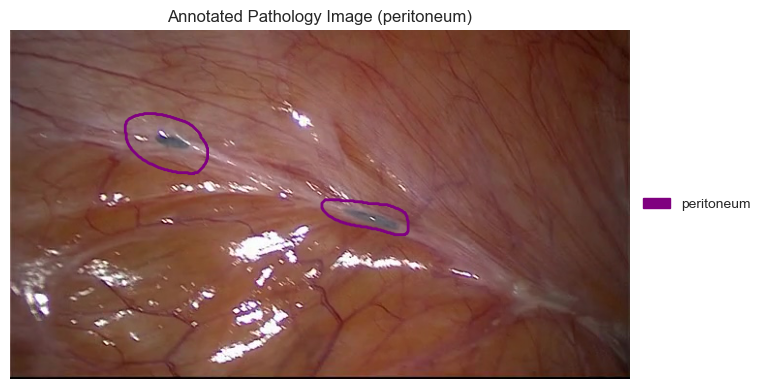

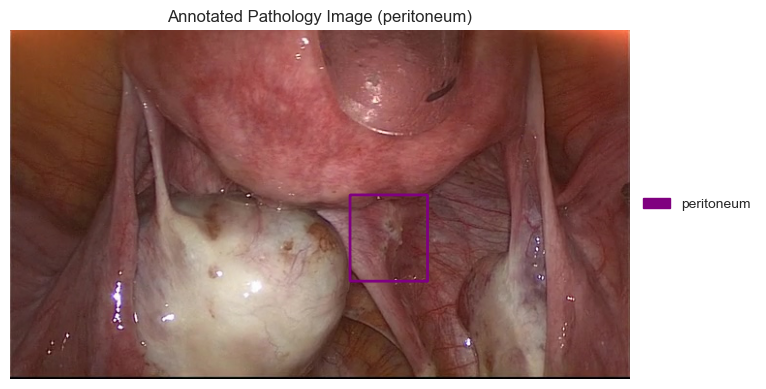

In [73]:
visualize_image_annotations(selected_annotation_groups)

Visual inspection of annotated regions suggests that some are easily interpretable and align with visually identifiable lesions, while others appear more ambiguous to a non-clinical observer. 
Some annotations encompassed larger anatomical regions (e.g., ovarian tissue), potentially reflecting clinically informed labeling decisions or diffuse pathology. Both observations are consistent with the inherent complexity of endometriosis and laparoscopic lesion identification. 

### 4.3 Multi-Label Image Annotation Visualization
Visualize images containing multiple lesion types and their corresponding annotations to examine co-occurring pathology patterns. 

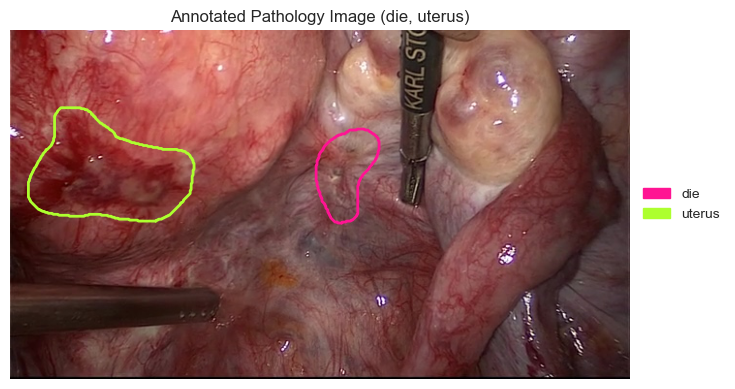

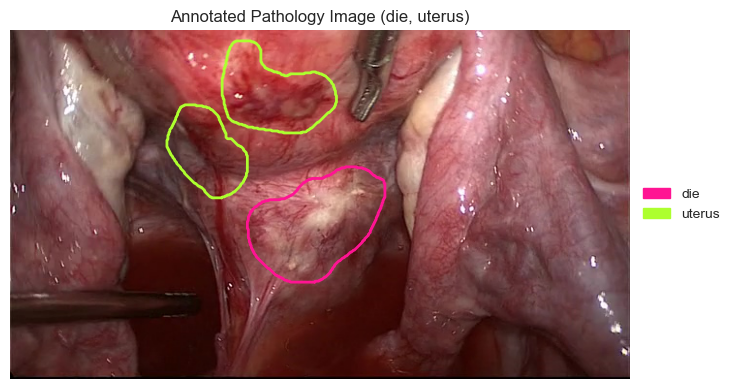

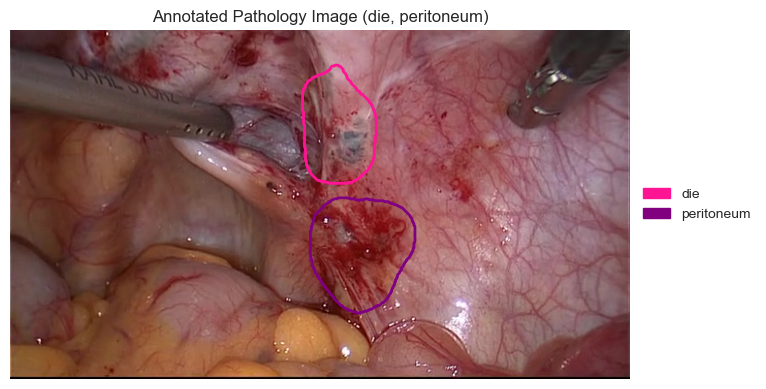

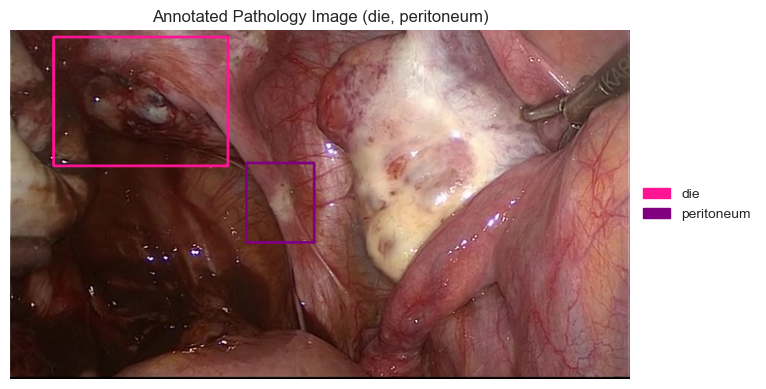

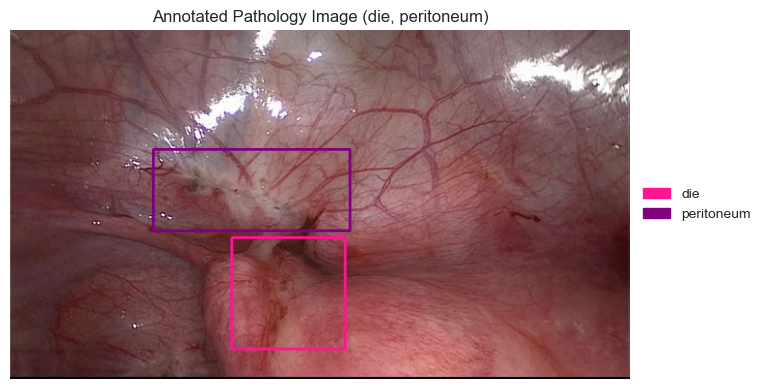

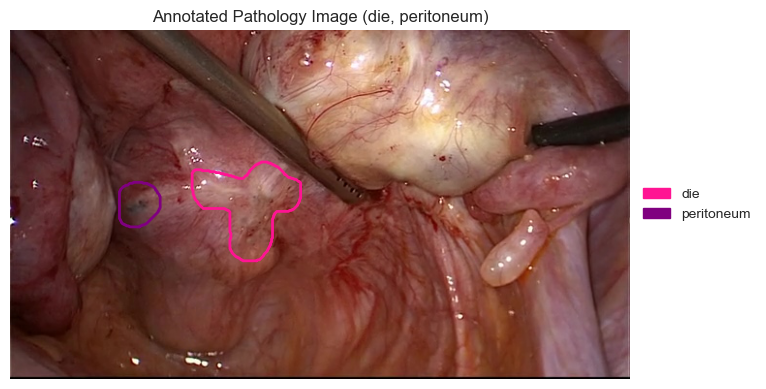

In [74]:
# Visualize multi-type lesion images + annotations
visualize_image_annotations(multi_label_groups)

Only six images contain multiple lesion types, meaning that multi-label cases are rare in the dataset. All multi-label images include die endometriosis annotations, co-occurring with either peritoneum (4 images) or uterus (2 images) annotations. No image contains more than two lesion classes, and no annotation overlap is observed. In the die and uterus examples, the uterus annotation appears in a distinct anatomical region from the die annotation. The spatial relationship between die and peritoneum annotations was less visually distinguishable. 

[↑ Back to Table of Contents](#Table-of-Contents)

## 5. Visual Image Quality Assessment
Visualize images with extreme values for the image quality metrics computed in Section [3. Image Quality and Color Metrics](#3.-Image-Quality-and-Color-Metrics) to assess their visual characteristics and identify potential image quality concerns. 

### 5.1 Brightness Extremes
Compare the brightest and darkest images in the dataset based on average pixel intensity.

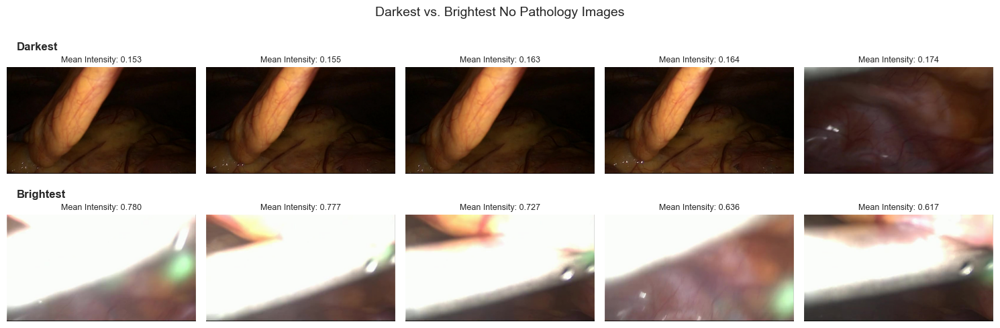

In [75]:
darkest_nopath_imgs = no_pathology_brightness_df.nsmallest(5, "mean_intensity")
brightest_nopath_imgs = no_pathology_brightness_df.nlargest(5, "mean_intensity")
compare_image_groups(group1 = darkest_nopath_imgs["img_path"].tolist(), 
                     group2 = brightest_nopath_imgs["img_path"].tolist(), 
                     group1_label = "Darkest", 
                     group2_label = "Brightest", 
                     group1_values = darkest_nopath_imgs["mean_intensity"].tolist(),
                     group2_values = brightest_nopath_imgs["mean_intensity"].tolist(),
                     value_label = "Mean Intensity",
                     title = "Darkest vs. Brightest No Pathology Images")

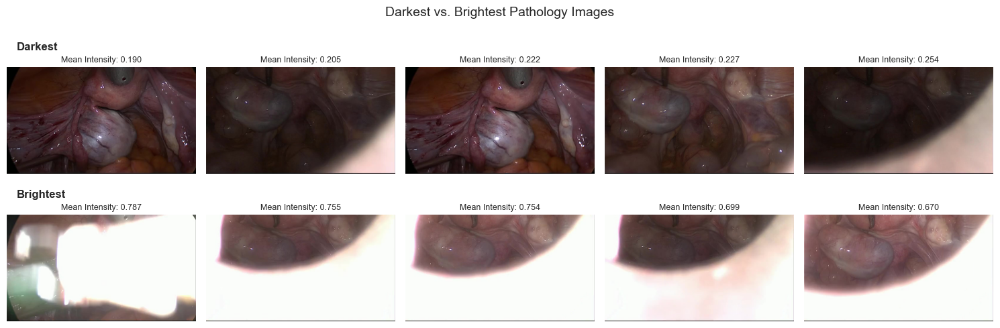

In [76]:
darkest_path_imgs = pathology_brightness_df.nsmallest(5, "mean_intensity")
brightest_path_imgs = pathology_brightness_df.nlargest(5, "mean_intensity")
compare_image_groups(group1 = darkest_path_imgs["img_path"].tolist(), 
                     group2 = brightest_path_imgs["img_path"].tolist(), 
                     group1_label = "Darkest", 
                     group2_label = "Brightest", 
                     group1_values = darkest_path_imgs["mean_intensity"].tolist(),
                     group2_values = brightest_path_imgs["mean_intensity"].tolist(),
                     value_label = "Mean Intensity",
                     title = "Darkest vs. Brightest Pathology Images")

Comparing the five darkest and brightest images reveals clear visual differences between brightness extremes. The darkest images are characterized by minimal light, with much of the surgical field obscured by shadows. The brightest images contain large regions of intense white light that obscure underlying anatomical structures. These extreme brightness variations may correspond to brief changes in laparoscopic lighting or reflections from nearby surgical instruments during surgery, contributing to underexposed and overexposed frames.

### 5.2 Contrast Extremes
Compare the lowest and highest contrast images in the dataset based on the standard deviation of grayscale pixel intensities across each image. 

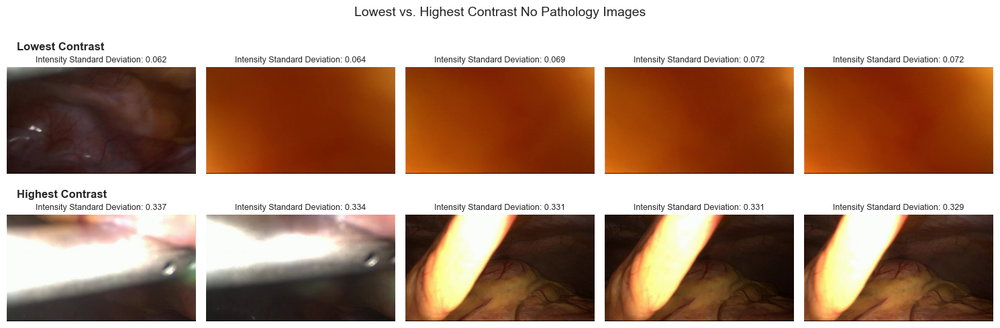

In [77]:
lowest_contrast_nopath_imgs = no_pathology_contrast_df.nsmallest(5, "contrast_std")
highest_contrast_nopath_imgs = no_pathology_contrast_df.nlargest(5, "contrast_std")
compare_image_groups(group1 = lowest_contrast_nopath_imgs["img_path"].tolist(), 
                     group2 = highest_contrast_nopath_imgs["img_path"].tolist(), 
                     group1_label = "Lowest Contrast", 
                     group2_label = "Highest Contrast", 
                     group1_values = lowest_contrast_nopath_imgs["contrast_std"].tolist(),
                     group2_values = highest_contrast_nopath_imgs["contrast_std"].tolist(),
                     value_label = "Intensity Standard Deviation",
                     title = "Lowest vs. Highest Contrast No Pathology Images")

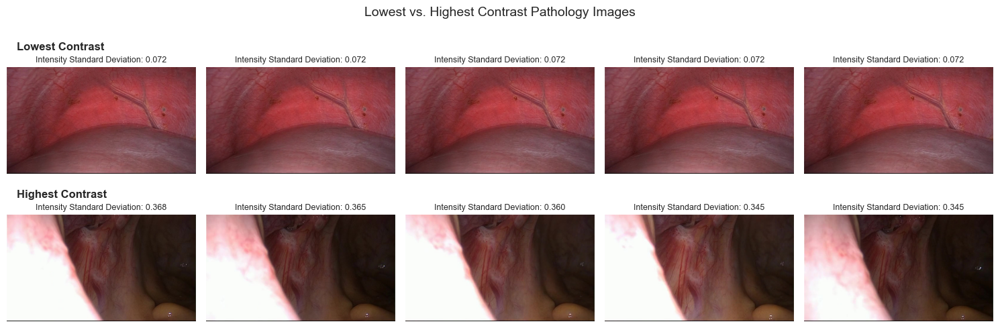

In [78]:
lowest_contrast_path_imgs = pathology_contrast_df.nsmallest(5, "contrast_std")
highest_contrast_path_imgs = pathology_contrast_df.nlargest(5, "contrast_std")
compare_image_groups(group1 = lowest_contrast_path_imgs["img_path"].tolist(), 
                     group2 = highest_contrast_path_imgs["img_path"].tolist(), 
                     group1_label = "Lowest Contrast", 
                     group2_label = "Highest Contrast", 
                     group1_values = lowest_contrast_path_imgs["contrast_std"].tolist(),
                     group2_values = highest_contrast_path_imgs["contrast_std"].tolist(),
                     value_label = "Intensity Standard Deviation",
                     title = "Lowest vs. Highest Contrast Pathology Images")

The contrast extremes show visual differences. Images with the lowest contrast appear flatter, with less distinction between dark and bright regions, whereas the highest contrast images display pronounced differences in intensity.

### 5.3 Sharpness Extremes
Compare the lowest and highest sharpness images in the dataset based on Laplacian variance. 

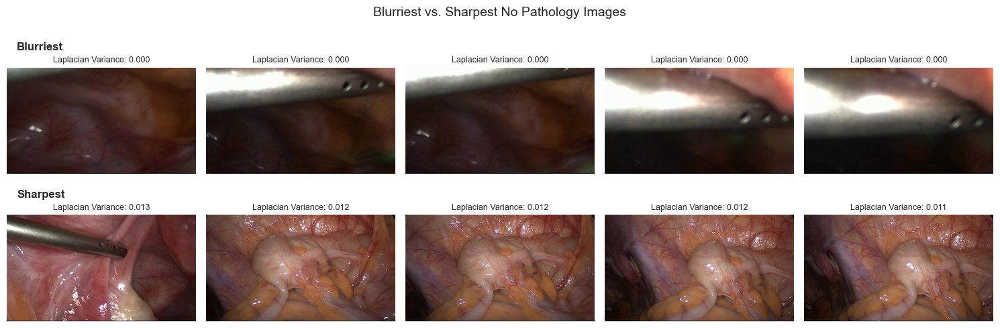

In [79]:
blurriest_nopath_imgs = no_pathology_sharpness_df.nsmallest(5, "laplacian_variance")
sharpest_nopath_imgs = no_pathology_sharpness_df.nlargest(5, "laplacian_variance")
compare_image_groups(group1 = blurriest_nopath_imgs["img_path"].tolist(), 
                     group2 = sharpest_nopath_imgs["img_path"].tolist(), 
                     group1_label = "Blurriest", 
                     group2_label = "Sharpest", 
                     group1_values = blurriest_nopath_imgs["laplacian_variance"].tolist(),
                     group2_values = sharpest_nopath_imgs["laplacian_variance"].tolist(),
                     value_label = "Laplacian Variance",
                     title = "Blurriest vs. Sharpest No Pathology Images")

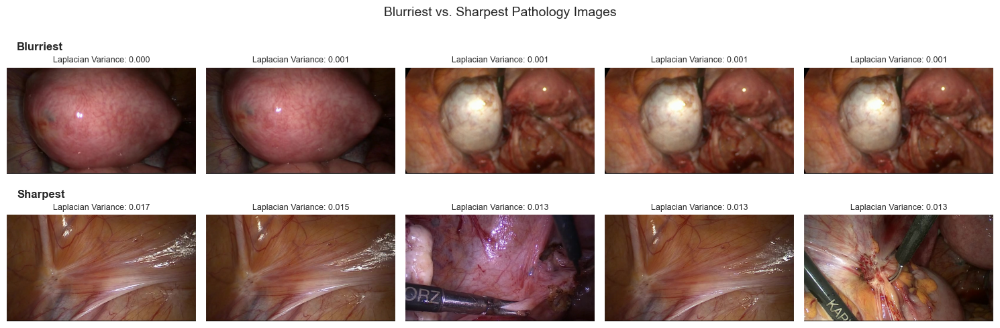

In [80]:
blurriest_path_imgs = pathology_sharpness_df.nsmallest(5, "laplacian_variance")
sharpest_path_imgs = pathology_sharpness_df.nlargest(5, "laplacian_variance")
compare_image_groups(group1 = blurriest_path_imgs["img_path"].tolist(), 
                     group2 = sharpest_path_imgs["img_path"].tolist(), 
                     group1_label = "Blurriest", 
                     group2_label = "Sharpest", 
                     group1_values = blurriest_path_imgs["laplacian_variance"].tolist(),
                     group2_values = sharpest_path_imgs["laplacian_variance"].tolist(),
                     value_label = "Laplacian Variance",
                     title = "Blurriest vs. Sharpest Pathology Images")

The five sharpest images from both subsets show noticeably greater detail and clearer anatomical boundaries than images with meaningfully lower Laplacian variances, indicating that there is clear variation in image sharpness across the dataset. 

### 5.4 Identified Data Characteristics and Quality Concerns
Summarize observations and quality concerns identified through visual inspection of metric extremes.

<u>1. Representativeness of Image Quality Extremes<u>
   
Although the images shown in this section represent metric extremes, the relatively narrow distributions across the image quality metrics calculated previously suggest that the examined metric extremes are not representative of the dataset as a whole, but instead reflect relatively uncommon observations. 

<u>2. Nearly Identical Frames<u>
   
Many of the identified extremes in both the no_pathology and pathology groups appear to originate from consecutive frames within the same surgical videos, resulting in nearly identical images. This recurring pattern of similar frames motivates further investigation through image similarity analysis to assess the degree of similarity and evaluate the extent of redundancy across the dataset.

<u>3. Visually Obstructed or Disrupted Frames<u>

Images were observed that appear to have been captured during moments when the camera view was temporarily obstructed or disrupted. Specifically, these images contain little to no discernible visual information, with the frame appearing largely covered or composed of indistinct colors rather than a clear view of the surgical area. Such images will require further evaluation during subsequent data preparation steps to determine how they should be handled.

<u>4. Frames Dominated by Surgical Instruments<u>

While many frames contain surgical instruments, some contain instruments that substantially obstruct the view of the surgical area. In these cases, the instruments or glare occupy a meaningful portion of the frame and limit the visibility of surrounding anatomy. These frames will need to be handled appropriately during data preparation.

<u>5. Variation in Image Sharpness<u>

Noticeable variation in image sharpness was observed among metric extremes, with some frames appearing meaningfully blurrier than others. The extent to which these lower-sharpness images may affect subsequent analyses will be addressed during data preparation. 

[↑ Back to Table of Contents](#Table-of-Contents)

## 6. Image Similarity and Redundancy Analysis
Assess similarity and redundancy in the GLENDA dataset by visualizing consecutive frames and performing SSIM analysis on both sequential and randomized pairs.

### 6.1 Visual Inspection of Consecutive Frames
Visualize and compare randomly selected groups of consecutive frames to assess similarity patterns within the dataset.

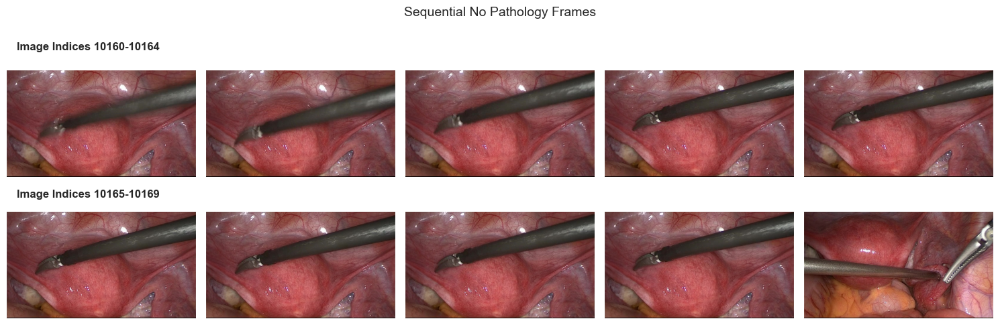

In [81]:
start = random.randint(0, len(no_pathology_images_clean) - 10)
sample = no_pathology_images_clean[start:start + 10]
compare_image_groups(
    group1 = sample[0:5],
    group2 = sample[5:10],
    group1_label = f"Image Indices {start}-{start + 4}",
    group2_label = f"Image Indices {start + 5}-{start + 9}",
    title = "Sequential No Pathology Frames"
)

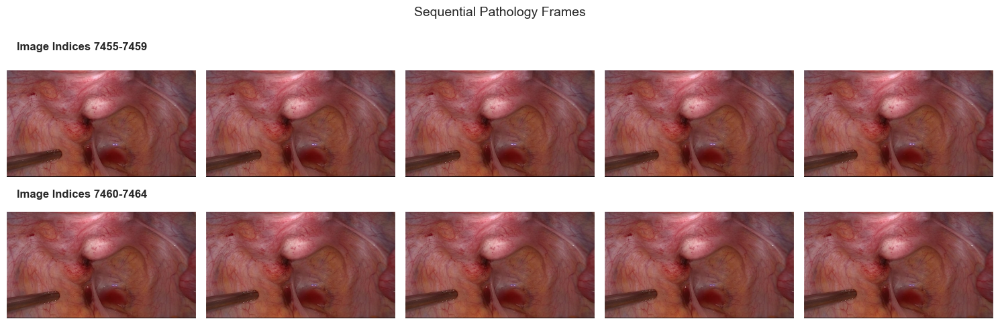

In [82]:
start = random.randint(0, len(pathology_images_clean) - 10)
sample = pathology_images_clean[start:start + 10]
compare_image_groups(
    group1 = sample[0:5],
    group2 = sample[5:10],
    group1_label = f"Image Indices {start}-{start + 4}",
    group2_label = f"Image Indices {start + 5}-{start + 9}",
    title = "Sequential Pathology Frames"
)

Visual inspection of multiple randomly selected sequences of consecutive images confirmed that adjacent frames appear highly similar. In many cases, anatomical structures, camera position, and lighting conditions remained largely unchanged.

### 6.2 SSIM Analysis
Evaluate visual redundancy within the dataset utilizing Structural Similarity Index Measure (SSIM). 

SSIM is composed of three components: luminance, contrast, and structure. 
- Luminance: compares the difference in average pixel intensity (brightness) between two images.
- Contrast: compares the difference in the spread of pixel intensities, measured by standard deviation.
- Structure: compares the spatial patterns between two images, after accounting for differences in luminance and contrast.
  
These components are combined into one value ranging from 0 to 1, where 1 indicates identical images.

#### 6.2.1 Sequential Frame Similarity

Sequential frame similarity was evaluated by calculating the SSIM between adjacent images in each video sequence. Images were grouped into `no_pathology_sequences` and `pathology_sequences` based on their parent video sequence directory (v_<vID>_s_<FROM-TO>). Within each sequence, images are ordered by their frame identifier (fID), such that images generally represent consecutive frames. This grouping ensures that SSIM comparisons are restricted to frames within the same sequence, preventing cross-sequence comparisons that would not represent sequential frame similarity. Sequences containing only one image were excluded from analysis as they cannot be compared. 

In [83]:
# Group no_pathology images by video sequence directory
no_pathology_sequences = defaultdict(list)
for path in no_pathology_images_clean:
    no_pathology_sequences[path.parent].append(path)

In [84]:
# Group pathology images by video sequence directory
pathology_sequences = defaultdict(list)
for path in pathology_images_clean:
    pathology_sequences[path.parent].append(path)

# Keep only pathology sequences containing at least 2 images for sequential comparison 
comparable_pathology_sequences = {}
for parent, paths in pathology_sequences.items():
    if len(paths) >= 2:
        comparable_pathology_sequences[parent] = paths


 SSIM Analysis
Average SSIM: 0.724
Std SSIM: 0.143
Min SSIM: 0.327
Max SSIM: 0.993


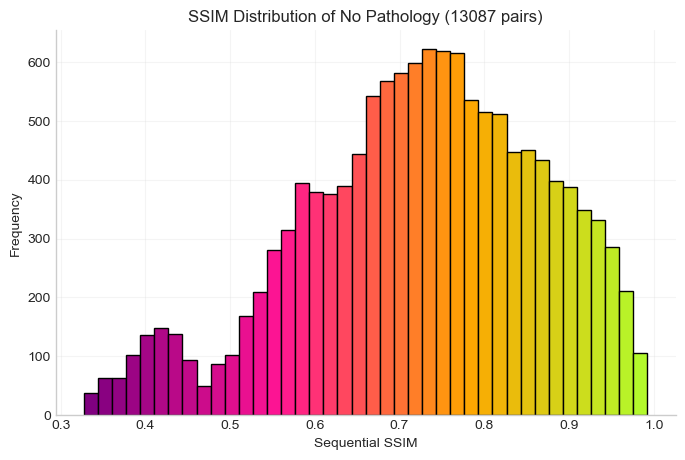

In [85]:
sequential_ssim_analysis(no_pathology_sequences, dataset_name = "No Pathology")

The no_pathology subset had an average SSIM of 0.724 across all adjacent frame comparisons within the 27 video sequences.


 SSIM Analysis
Average SSIM: 0.766
Std SSIM: 0.144
Min SSIM: 0.283
Max SSIM: 0.994


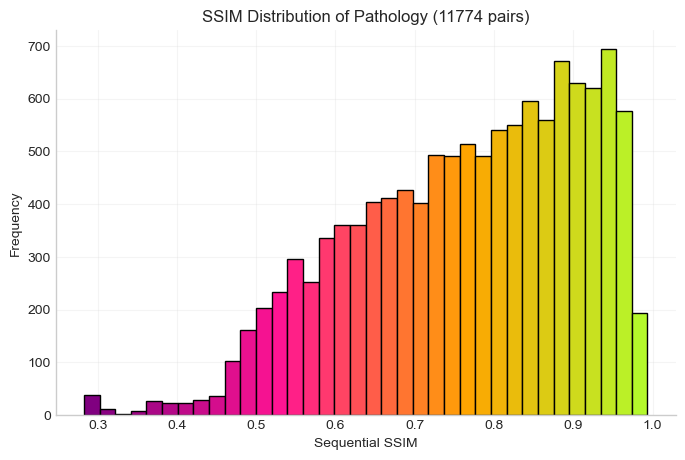

In [86]:
sequential_ssim_analysis(comparable_pathology_sequences, dataset_name = "Pathology")

Since many of the pathology sequences contain only one image, these sequences were excluded, resulting in comparisons across 108 sequences. The pathology subset had an average SSIM of 0.766 across all adjacent frame comparisons within these sequences.

Overall, the sequential SSIM analysis demonstrates that, on average, adjacent frames share an undeniable degree of structural resemblance in both subsets. This observation may be related to the video-derived nature of the dataset, where images were extracted from laparoscopic video sequences and organized according to frame order. The pathology subset had a slightly higher average SSIM than the no_pathology subset (0.766 vs. 0.724). 

#### 6.2.2 Randomized Frame Similarity

To determine whether the structural similarity observed in sequential analysis was primarily influenced by frame ordering, the SSIM analysis was repeated after randomly shuffling the images for both subsets. Randomization removes the consecutive relationship between neighboring frames, providing a measure of structural similarity that is independent of sequential ordering.


 SSIM Analysis
Average SSIM: 0.443
Std SSIM: 0.060
Min SSIM: 0.235
Max SSIM: 0.763


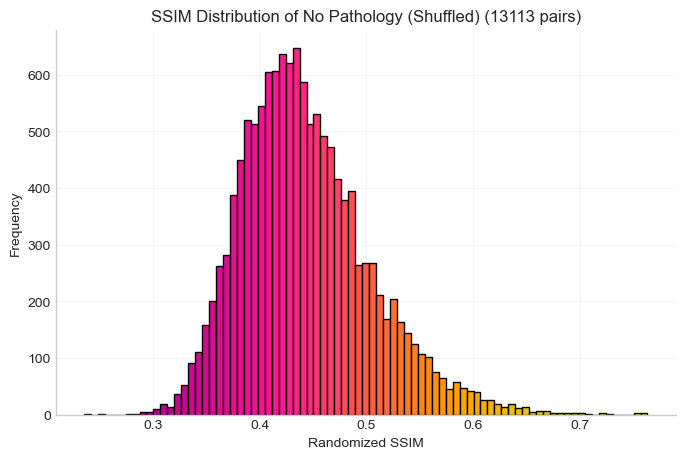

In [87]:
no_pathology_randomized = []
for paths in no_pathology_sequences.values():
    for path in paths:
        no_pathology_randomized.append(path)

random.shuffle(no_pathology_randomized)
randomized_ssim_analysis(no_pathology_randomized, n_pairs = len(no_pathology_randomized) - 1, dataset_name = "No Pathology (Shuffled)")

A randomized comparison of the no_pathology group reduced the average SSIM score from 0.724 to 0.443, a 38.8% decrease.


 SSIM Analysis
Average SSIM: 0.397
Std SSIM: 0.075
Min SSIM: 0.227
Max SSIM: 0.938


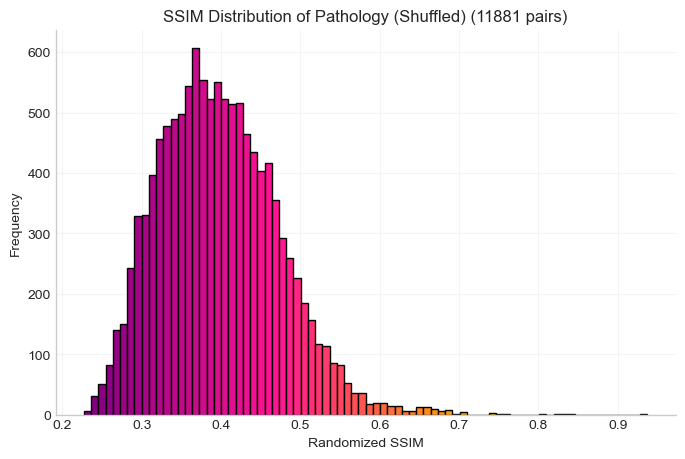

In [88]:
pathology_randomized = []
for paths in comparable_pathology_sequences.values():
    for path in paths:
        pathology_randomized.append(path)

random.shuffle(pathology_randomized)
randomized_ssim_analysis(pathology_randomized, n_pairs = len(pathology_randomized) - 1, dataset_name = "Pathology (Shuffled)")

A randomized comparison of the pathology group reduced the average SSIM score from 0.766 to 0.397, a 48.2% decrease.

Overall, the SSIM analysis revealed two key observations:
* The original image order was associated with noticeably higher average similarity scores between sequential frames than randomized image pairs.
* After randomizing the image order, the dataset still produced a measurable level of structural similarity, which could be related to shared visual characteristics across surgical images, such as anatomical structures and imaging conditions, as well as residual redundancy among frames. However, the substantial reduction in similarity after randomization suggests that the high similarity observed between sequential frames is associated with the original frame order.

[↑ Back to Table of Contents](#Table-of-Contents)

### Summary of EDA Findings

1. Dataset Composition and Structure:
   - **Peritoneum is by far the most represented lesion class in the dataset.** The dataset has an uneven distribution of lesion classes. Peritoneum annotations are substantially more common than die, ovary, and uterus annotations. This imbalance is reflected at both the annotation and image level. The higher prevalence of peritoneum annotations is notable, given that peritoneal endometriosis is often clinically described as the most common subtype of endometriosis. It's possible that this distribution could partially reflect real-world prevalence. 
   - **Video sequences in the dataset are not independent.** Identical images were identified across distinct video sequences. Exact duplicate images were found in both the no_pathology and pathology groups, including images with the same frame identifier but different video identifiers. The presence of identical images across sequences demonstrates that the sequences do not represent independent surgical observations. As a result, the total number of sequences does not accurately reflect the number of unique surgical cases represented in the dataset.
   - **Most images contain relatively few annotations.** Annotation density is distributed towards the lower end, with most images containing one, two, or three annotations.
   - **Peritoneum has the highest observed annotation density.** A small number of images contain substantially more annotations, with the highest observed density being nine for the peritoneum class, compared with a maximum of two or three for the other lesion classes.

2. Lesion Annotation Characteristics:
   - **Annotation sizes vary across lesion types.** Ovary annotations have the largest average area, while peritoneum annotations have the smallest average area. Box plots show differences in the distributions of annotation areas, including meaningful differences in their ranges, central distributions, and outliers. This indicates that lesion types are represented by annotations of different sizes, which may reflect differences in annotation practices or anatomical structures.
   - **Most annotations occupy relatively small areas.** Across all lesion types, the majority are concentrated towards the lower end of the range of annotation areas, resulting in a strongly right-skewed distribution and indicating that smaller annotated regions are more common in the dataset.
   - **Peritoneum has the largest number of annotation-area outliers, which may be influenced by its larger class size.** Peritoneum has substantially more outliers than the other lesion groups, but its larger class size means that the proportion of annotation outliers is not as high.
   - **Annotation locations are concentrated more towards the center of the image.** Centroids occur most frequently towards the middle of the frame, with frequencies generally decreasing farther from the center. The spatial distribution is more spread horizontally than vertically, which lines up with the wider horizontal dimension of the frames. This indicates that images are not uniformly distributed across the entire image and are more frequently represented near the center of the surgical field than toward the edges. This pattern may reflect how the camera is positioned to visualize areas of interest during surgery. 

3. Image Quality and Color Metrics:
   - **Images had relatively low brightness overall.** Measured using average grayscale pixel intensity, both the no_pathology and pathology image groups showed relatively low overall brightness. This may reflect the lighting conditions during laparoscopic surgery, where a small light illuminates the surgical field while the surrounding areas remain relatively dark. The relatively low brightness therefore appears to be a characteristic of the imaging environment rather than an indication of poor image quality.
   - **Contrast was not a strong distinguishing characteristic between image groups.** Although pathology images might be expected to exhibit greater contrast because endometriosis lesions can appear as dark red or black regions, the measured contrast distributions were very similar between the no_pathology and pathology groups. The pathology group only showed very small increases in average contrast, with differences of 0.005 when measured using the standard deviation and 0.021 when measured using the 95th-5th percentile range of pixel intensities. This suggests that overall image contrast alone does not strongly distinguish images with pathology from those without pathology in this dataset.
   - **Images exhibited higher red pixel intensities.** Comparing the distributions of red, green, and blue pixel intensities, both image groups showed noticeably higher red intensities overall. This pattern may reflect the predominantly red and pink natural coloration of many anatomical structures and organs visible within the surgical field. The similarity between the two image groups also suggests that higher red intensity is characteristic of the laparoscopic images rather than a feature specific to pathology status.

4. Visual Exploration and Annotation Visualization:
   - **Many pathology images feature dark red and black regions.** Compared with the no_pathology images, which generally showed more typical anatomical features, many pathology images contained visually distinct dark red and black regions that may correspond to areas of endometriosis. This provides a noticeable visual characteristic of the pathology group, although these observations alone cannot confirm lesion presence.
   - **Some annotations were easier to interpret visually than others.** Many annotations clearly corresponded to noticeable regions, consisting of white, red, or black areas, while others were more difficult to distinguish from the surrounding tissue. This observation highlights the visual complexity of identifying endometriosis in a surgical setting. Since the dataset annotations were produced by clinical experts, the presence of visually ambiguous regions also indicates that identifying pathology from appearance alone can be challenging, even when expert annotations are available.
   - **DIE annotations were present in every multi-label representation.** All six images containing annotations from multiple lesion categories included at least one DIE annotation. Unlike peritoneum, ovary, and uterus, which describe anatomical locations, DIE describes a form of endometriosis characterized by deeper tissue infiltration and may therefore occur alongside lesions associated with different regions. The consistent appearance of DIE in multi-label images may reflect this difference in how the categories represent endometriosis lesion characteristics. 

5. Image Quality Assessment:
   - **Metric extremes represented less typical image quality characteristics, identifying problematic frames.** Visualization of the extreme values identified images with noticeably unusual brightness, contrast, or sharpness compared with the rest of the dataset. However, the relatively narrow distributions of the image quality metrics indicate that these extreme instances are not representative of the dataset as a whole.
   - **Near-identical images were frequently observed among metric extremes.** When visualizing images with extreme image-quality measurements, many highly similar frames were observed, suggesting that some of the unusual image quality characteristics may occur across consecutive or closely related frames.
   - **There are images with visual obstruction and disruption that make it difficult to observe the contents of the frame.** Likely due to movement during surgery, some frames are obstructed, dominated by surgical instruments and/or glare, or affected by lighting conditions that make it challenging to discern the contents of the image. Because these frames contain little to no meaningful visual information with respect to the pathology or surgical field, they need to be handled appropriately prior to modeling.

6. Image Similarity and Redundancy:
   - **Visualization of random samples of sequential frames reveals that they are highly similar.** Because the dataset images were extracted as frames from surgical videos, consecutive frames often contain nearly identical visual information. This raises concerns for subsequent modeling, as including highly similar frames across training and validation sets could result in data leakage and lead to overly optimistic model performance.
   - **Sequential frames exhibited substantially higher structural similarity than randomly paired images.** The original image ordering produced noticeably higher average SSIM scores between sequential frames than the randomized comparisons. For example, the no_pathology group had an average SSIM of 0.724 for sequential frames, compared with 0.443 after randomization. This demonstrates that consecutive frames extracted from surgical videos often contain highly similar visual information.
   - **Randomly paired images retained a measurable level of structural similarity** Randomly paired images still contained measurable structural similarity, which may reflect shared visual characteristics across surgical images, such as common anatomical structures and imaging conditions, as well as any remaining redundancy.
   - **High structural similarity is largely associated with the original frame ordering.** The substantial reduction in average SSIM after randomization demonstrates that the particularly high structural similarity observed between consecutive frames is largely related to their sequential nature rather than being representative of randomly paired images throughout the dataset.

### Overall Dataset Considerations

The GLENDA dataset consists of individual frames extracted from gynecologic laparoscopy videos. As a result, frames are derived from shared surgical procedures and may exhibit substantial structural similarities.

Patient or procedure identifiers were not available for this analysis, so most analyses were conducted at the individual-frame level. Visual inspection of consecutive frames and SSIM analysis demonstrated the presence of highly similar images within the dataset, particularly among sequential frames. These characteristics should be considered when interpreting descriptive statistics, as individual frames do not necessarily represent independent surgical observations  and may give a misleading impression of the number of unique surgical cases represented in the dataset. 

Additionally, these concerns will be addressed during data preparation and splitting prior to future modeling to reduce the risk of information leakage and ensure that model evaluation more accurately reflects performance on independent surgical observations. 